# G-Yan! Credit Risk Analytics — CRISP-DM Phase 3: Executive Visualization Portfolio & Forensic Model Audit
**Institution:** Gordon College — College of Computer Studies (Olongapo City)  
**Course:** CSE315 (45621 - CSP315A/L) Data Science | **Submitted To:** Mr. Simon Granil  
**By Group 4 (BSCS 3-A):** Canlas, Julce Lian E. | Edrosalan, Dale Cyrus D. | Ortega, James Dominic T. | Reguindin, Gian Karlo C.  
**Assigned Fictional Company:** **G-Yan!** (*FinTech Startup Track*)  
**Code Repository:** [https://github.com/Nykt04/cse315-group4-gyan-credit-risk](https://github.com/Nykt04/cse315-group4-gyan-credit-risk)

---

### Portfolio Overview
This notebook synthesizes all Phase 1 and Phase 2 artifacts (`UCI_Credit_Card_Clean_Integrated.csv`, `UCI_Credit_Card_Preprocessed_Train/Test.csv`, `model_artifacts.pkl`, `Model_Experiment_Log.csv`, `Association_Rules_Log.csv`, and `KMeans_Experiment_Log.csv`) into **8 publication-grade (300 DPI) visualizations** and a **forensic fairness & ROI summary** (`phase3_metrics_summary.json`):
1. **Figure 1 (`fig01_executive_dashboard.png`):** Executive Credit Risk Dashboard (Class Imbalance, Limit Quartiles, `PAY_0` Delinquency Cliff, Demographic Stratification)
2. **Figure 2 (`fig02_longitudinal_trajectory.png`):** 6-Month Longitudinal Billing/Payment Skew & Utilization/Delinquency Escalation
3. **Figure 3 (`fig03_correlation_and_network.png`):** Correlation Matrix Heatmap & NetworkX Credit Risk Feature Topology
4. **Figure 4 (`fig04_clustering_and_apriori.png`):** Behavioral Risk Personas (`KMeans`, $k=4$) & Top `mlxtend` Apriori Association Rules
5. **Figure 5 (`fig05_model_benchmark_and_tuning.png`):** Six-Family `scikit-learn` Model Benchmark & Iterative Tuning Gains
6. **Figure 6 (`fig06_roc_pr_and_confusion_matrices.png`):** Forensic Evaluation Panel — ROC Curves, Precision-Recall Curves & Dual-Policy Confusion Matrices (`EXP-10` vs. `EXP-10B`)
7. **Figure 7 (`fig07_feature_importance_and_threshold_roi.png`):** Champion `GradientBoostingClassifier` Feature Importance & Operating Threshold Tradeoff Analysis
8. **Figure 8 (`fig08_fairness_and_bias_audit.png`):** Ethical & Forensic Fairness Audit — Champion Model Recall (TPR) & False Positive Rate (FPR) Across Gender and Education Tiers


In [1]:
# Step 1: Load Phase 1 & Phase 2 Verified Artifacts
import json
import os
import pickle
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings("ignore")
os.makedirs("charts", exist_ok=True)

# Cohesive G-Yan! Brand Palette
NAVY = "#0F2C59"
LIGHT_NAVY = "#3B6998"
TEAL = "#1E6F72"
CORAL = "#C0392B"
AMBER = "#D97706"
SLATE = "#64748B"
BG_LIGHT = "#F8FAFC"
GRID_COL = "#CBD5E1"
INK = "#1E293B"
NL = chr(10)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

# Load Phase 1 & Phase 2 outputs (automatically checks both folder roots and FINAL COPIES subfolders)
SEARCH_DIRS = [
    os.path.abspath("../../PHASE1/FINAL COPIES"),
    os.path.abspath("../../PHASE1"),
    os.path.abspath("../../PHASE2/FINAL COPIES"),
    os.path.abspath("../../PHASE2"),
    os.path.abspath("../PHASE1/FINAL COPIES"),
    os.path.abspath("../PHASE1"),
    os.path.abspath("../PHASE2/FINAL COPIES"),
    os.path.abspath("../PHASE2"),
    os.path.abspath("."),
]

def find_artifact(filename: str) -> str:
    for d in SEARCH_DIRS:
        p = os.path.join(d, filename)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Could not locate {filename} in {SEARCH_DIRS}")

raw_df = pd.read_csv(find_artifact("UCI_Credit_Card_Raw.csv"))
df_clean = pd.read_csv(find_artifact("UCI_Credit_Card_Clean_Integrated.csv"))
train_df = pd.read_csv(find_artifact("UCI_Credit_Card_Preprocessed_Train.csv"))
val_df = pd.read_csv(find_artifact("UCI_Credit_Card_Preprocessed_Test.csv"))

exp_df = pd.read_csv(find_artifact("Model_Experiment_Log.csv"))
assoc_df = pd.read_csv(find_artifact("Association_Rules_Log.csv"))
kmeans_df = pd.read_csv(find_artifact("KMeans_Experiment_Log.csv"))

with open(find_artifact("model_artifacts.pkl"), "rb") as f:
    artifacts = pickle.load(f)

feature_names = artifacts["feature_names"]
X_val = val_df[feature_names].to_numpy(dtype=float)
y_val = val_df["default"].to_numpy(dtype=int)

# Extract trained models & validation probabilities
models = artifacts["predictive_models"]
gb_entry = models["gradient_boosting_champion"]
gb_model = gb_entry["model"]
thr_f1 = gb_entry["threshold_f1"]
thr_rec70 = gb_entry["threshold_recall70"]

p_gb = gb_model.predict_proba(X_val)[:, 1]
p_rf = models["random_forest_tuned"]["model"].predict_proba(X_val)[:, 1]
p_mlp = models["mlp_deep_tuned"]["model"].predict_proba(X_val)[:, 1]
p_lr = models["logistic_regression_tuned"]["model"].predict_proba(X_val)[:, 1]
p_dt = models["decision_tree_pruned"]["model"].predict_proba(X_val)[:, 1]
p_lda = models["lda_shrinkage"]["model"].predict_proba(X_val)[:, 1]

# Recreate k=4 cluster labels using the exact fitted Phase 2 KMeans scaler + model
km_feats = ["limit_bal", "avg_utilization_6m", "payment_to_bill_ratio_6m", "delinquency_months_count", "cumulative_delay_score"]
X_c = artifacts["descriptive_artifacts"]["kmeans_scaler"].transform(df_clean[km_feats].to_numpy(dtype=float))
df_clean["cluster_k4"] = artifacts["descriptive_artifacts"]["kmeans_k4_model"].predict(X_c)

print(f"[LOADED] Raw: {raw_df.shape} | Clean: {df_clean.shape} | Val: {X_val.shape}")
print(f"[LOADED] Champion GBDT ROC-AUC = {roc_auc_score(y_val, p_gb):.4f}, PR-AUC = {average_precision_score(y_val, p_gb):.4f}")
print(f"[LOADED] Policy thresholds -> F1-Optimal: {thr_f1} | Recall>=0.70: {thr_rec70}")


[LOADED] Raw: (30000, 25) | Clean: (29965, 33) | Val: (7492, 45)
[LOADED] Champion GBDT ROC-AUC = 0.7830, PR-AUC = 0.5664
[LOADED] Policy thresholds -> F1-Optimal: 0.61 | Recall>=0.70: 0.42


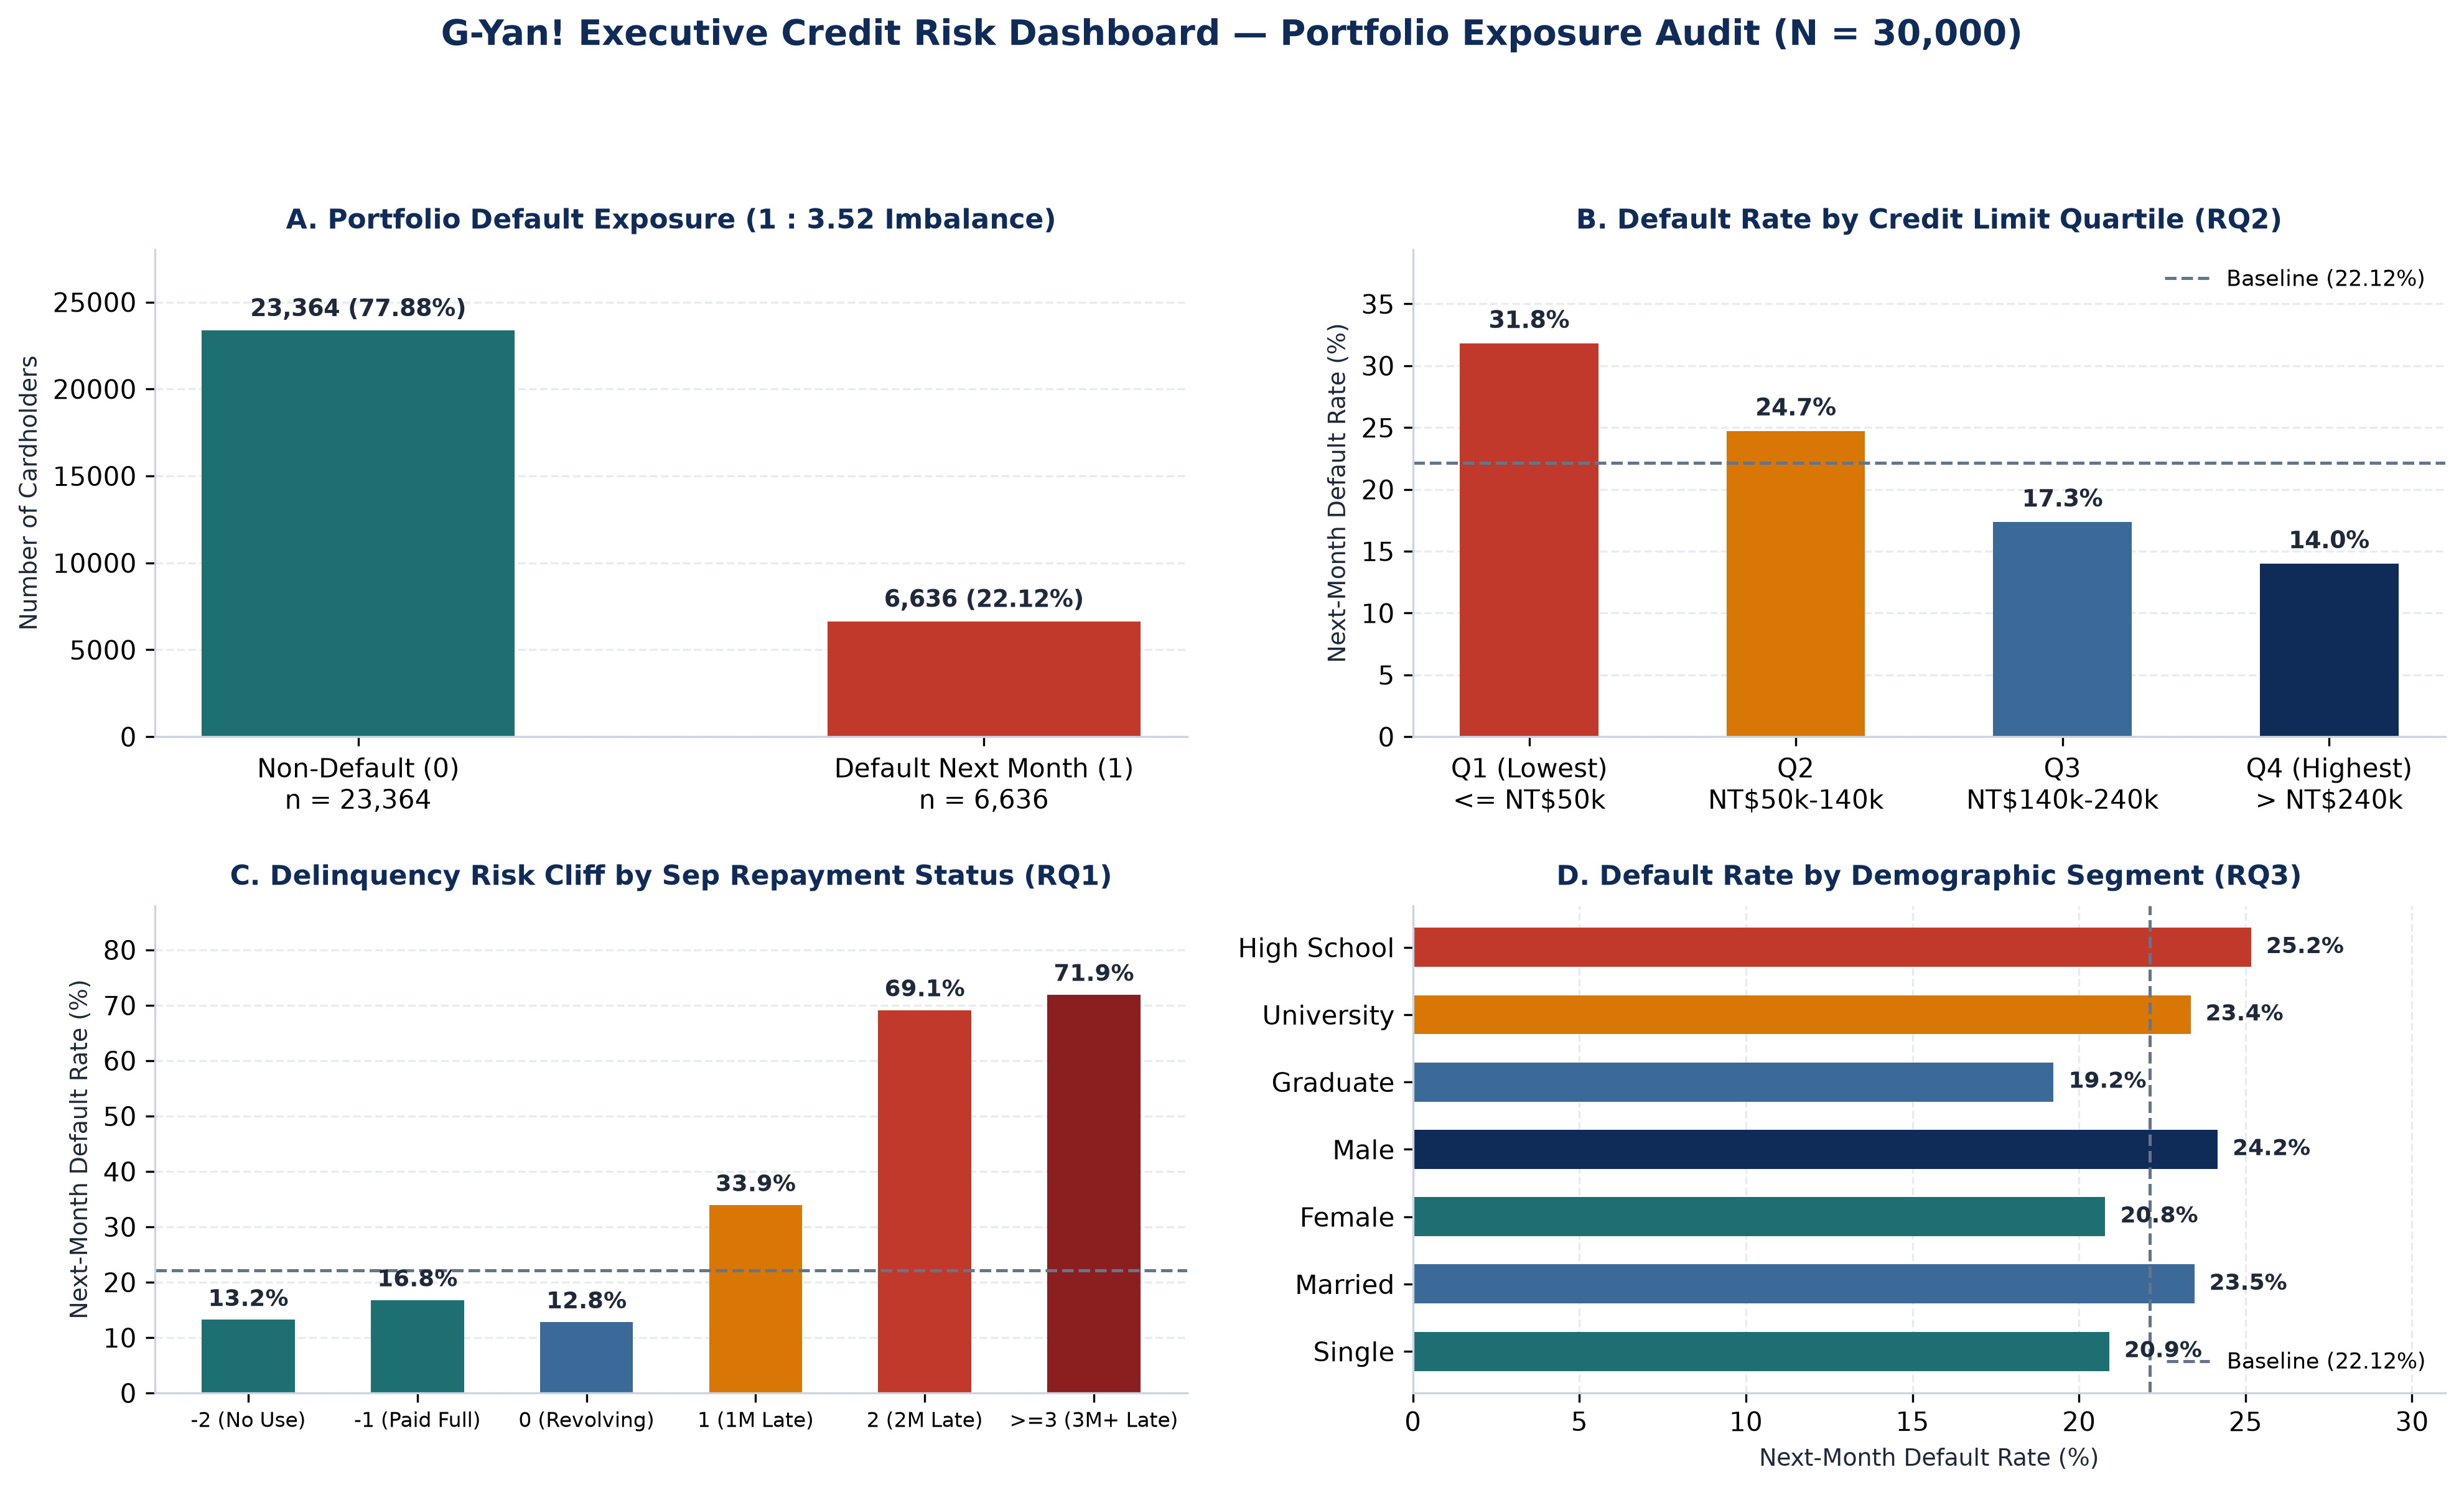

[SAVED] charts/fig01_executive_dashboard.png


In [2]:
# Figure 1: Executive Credit Risk Dashboard (4-Panel Overview)
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2), dpi=300)
fig.suptitle("G-Yan! Executive Credit Risk Dashboard — Portfolio Exposure Audit (N = 30,000)",
             fontsize=13.5, fontweight="bold", color=NAVY, y=0.98)

t_col = "default payment next month"
base_rate = raw_df[t_col].mean() * 100

# Panel A: Target Class Imbalance
ax = axes[0, 0]
c0, c1 = int((raw_df[t_col] == 0).sum()), int((raw_df[t_col] == 1).sum())
bars = ax.bar([f"Non-Default (0){NL}n = {c0:,}", f"Default Next Month (1){NL}n = {c1:,}"], [c0, c1], color=[TEAL, CORAL], width=0.5)
ax.set_title("A. Portfolio Default Exposure (1 : 3.52 Imbalance)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax.set_ylabel("Number of Cardholders", fontsize=9.0, color=INK)
ax.set_ylim(0, c0 * 1.20)
ax.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for b, cnt in zip(bars, [c0, c1]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 500, f"{cnt:,} ({cnt/len(raw_df)*100:.2f}%)",
            ha="center", va="bottom", fontsize=9.2, fontweight="bold", color=INK)

# Panel B: Default Rate by Credit Limit Quartile
ax = axes[0, 1]
q_bins = pd.cut(raw_df["LIMIT_BAL"], bins=[0, 50000, 140000, 240000, float("inf")])
q_rates = (raw_df.groupby(q_bins, observed=False)[t_col].mean() * 100).tolist()
q_labels = [f"Q1 (Lowest){NL}<= NT$50k", f"Q2{NL}NT$50k-140k", f"Q3{NL}NT$140k-240k", f"Q4 (Highest){NL}> NT$240k"]
bars = ax.bar(q_labels, q_rates, color=[CORAL, AMBER, LIGHT_NAVY, NAVY], width=0.52)
ax.axhline(base_rate, color=SLATE, linestyle="--", linewidth=1.2, label=f"Baseline ({base_rate:.2f}%)")
ax.set_title("B. Default Rate by Credit Limit Quartile (RQ2)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax.set_ylabel("Next-Month Default Rate (%)", fontsize=9.0, color=INK)
ax.set_ylim(0, max(q_rates) * 1.24)
ax.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=8.5)
for b, r in zip(bars, q_rates):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{r:.1f}%", ha="center", va="bottom", fontsize=9.2, fontweight="bold", color=INK)

# Panel C: Default Rate Cliff by Sep Repayment Status (PAY_0)
ax = axes[1, 0]
pay_groups = [
    ("-2 (No Use)", raw_df["PAY_0"] == -2, TEAL),
    ("-1 (Paid Full)", raw_df["PAY_0"] == -1, TEAL),
    ("0 (Revolving)", raw_df["PAY_0"] == 0, LIGHT_NAVY),
    ("1 (1M Late)", raw_df["PAY_0"] == 1, AMBER),
    ("2 (2M Late)", raw_df["PAY_0"] == 2, CORAL),
    (">=3 (3M+ Late)", raw_df["PAY_0"] >= 3, "#8B1E1E"),
]
p_lbls = [g[0] for g in pay_groups]
p_rates = [raw_df.loc[g[1], t_col].mean() * 100 for g in pay_groups]
p_cols = [g[2] for g in pay_groups]
bars = ax.bar(p_lbls, p_rates, color=p_cols, width=0.55)
ax.axhline(base_rate, color=SLATE, linestyle="--", linewidth=1.2)
ax.set_title("C. Delinquency Risk Cliff by Sep Repayment Status (RQ1)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax.set_ylabel("Next-Month Default Rate (%)", fontsize=9.0, color=INK)
ax.set_ylim(0, 88)
ax.tick_params(axis="x", labelsize=8.0)
ax.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for b, r in zip(bars, p_rates):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{r:.1f}%", ha="center", va="bottom", fontsize=8.8, fontweight="bold", color=INK)

# Panel D: Socio-Demographic Default Stratification (RQ3)
ax = axes[1, 1]
demo_groups = [
    ("High School", df_clean["education"] == 3, CORAL),
    ("University", df_clean["education"] == 2, AMBER),
    ("Graduate", df_clean["education"] == 1, LIGHT_NAVY),
    ("Male", df_clean["sex"] == 1, NAVY),
    ("Female", df_clean["sex"] == 2, TEAL),
    ("Married", df_clean["marriage"] == 1, LIGHT_NAVY),
    ("Single", df_clean["marriage"] == 2, TEAL),
]
d_lbls = [g[0] for g in demo_groups][::-1]
d_rates = [df_clean.loc[g[1], "default"].mean() * 100 for g in demo_groups][::-1]
d_cols = [g[2] for g in demo_groups][::-1]
bars = ax.barh(d_lbls, d_rates, color=d_cols, height=0.58)
ax.axvline(base_rate, color=SLATE, linestyle="--", linewidth=1.2, label=f"Baseline ({base_rate:.2f}%)")
ax.set_title("D. Default Rate by Demographic Segment (RQ3)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax.set_xlabel("Next-Month Default Rate (%)", fontsize=9.0, color=INK)
ax.set_xlim(0, 31)
ax.grid(axis="x", linestyle="--", alpha=0.45, color=GRID_COL)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=8.3)
for b, r in zip(bars, d_rates):
    ax.text(b.get_width() + 0.45, b.get_y() + b.get_height()/2, f"{r:.1f}%", va="center", fontsize=8.6, fontweight="bold", color=INK)

plt.tight_layout(rect=[0, 0, 1, 0.94], pad=1.8)
plt.savefig("charts/fig01_executive_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig01_executive_dashboard.png")


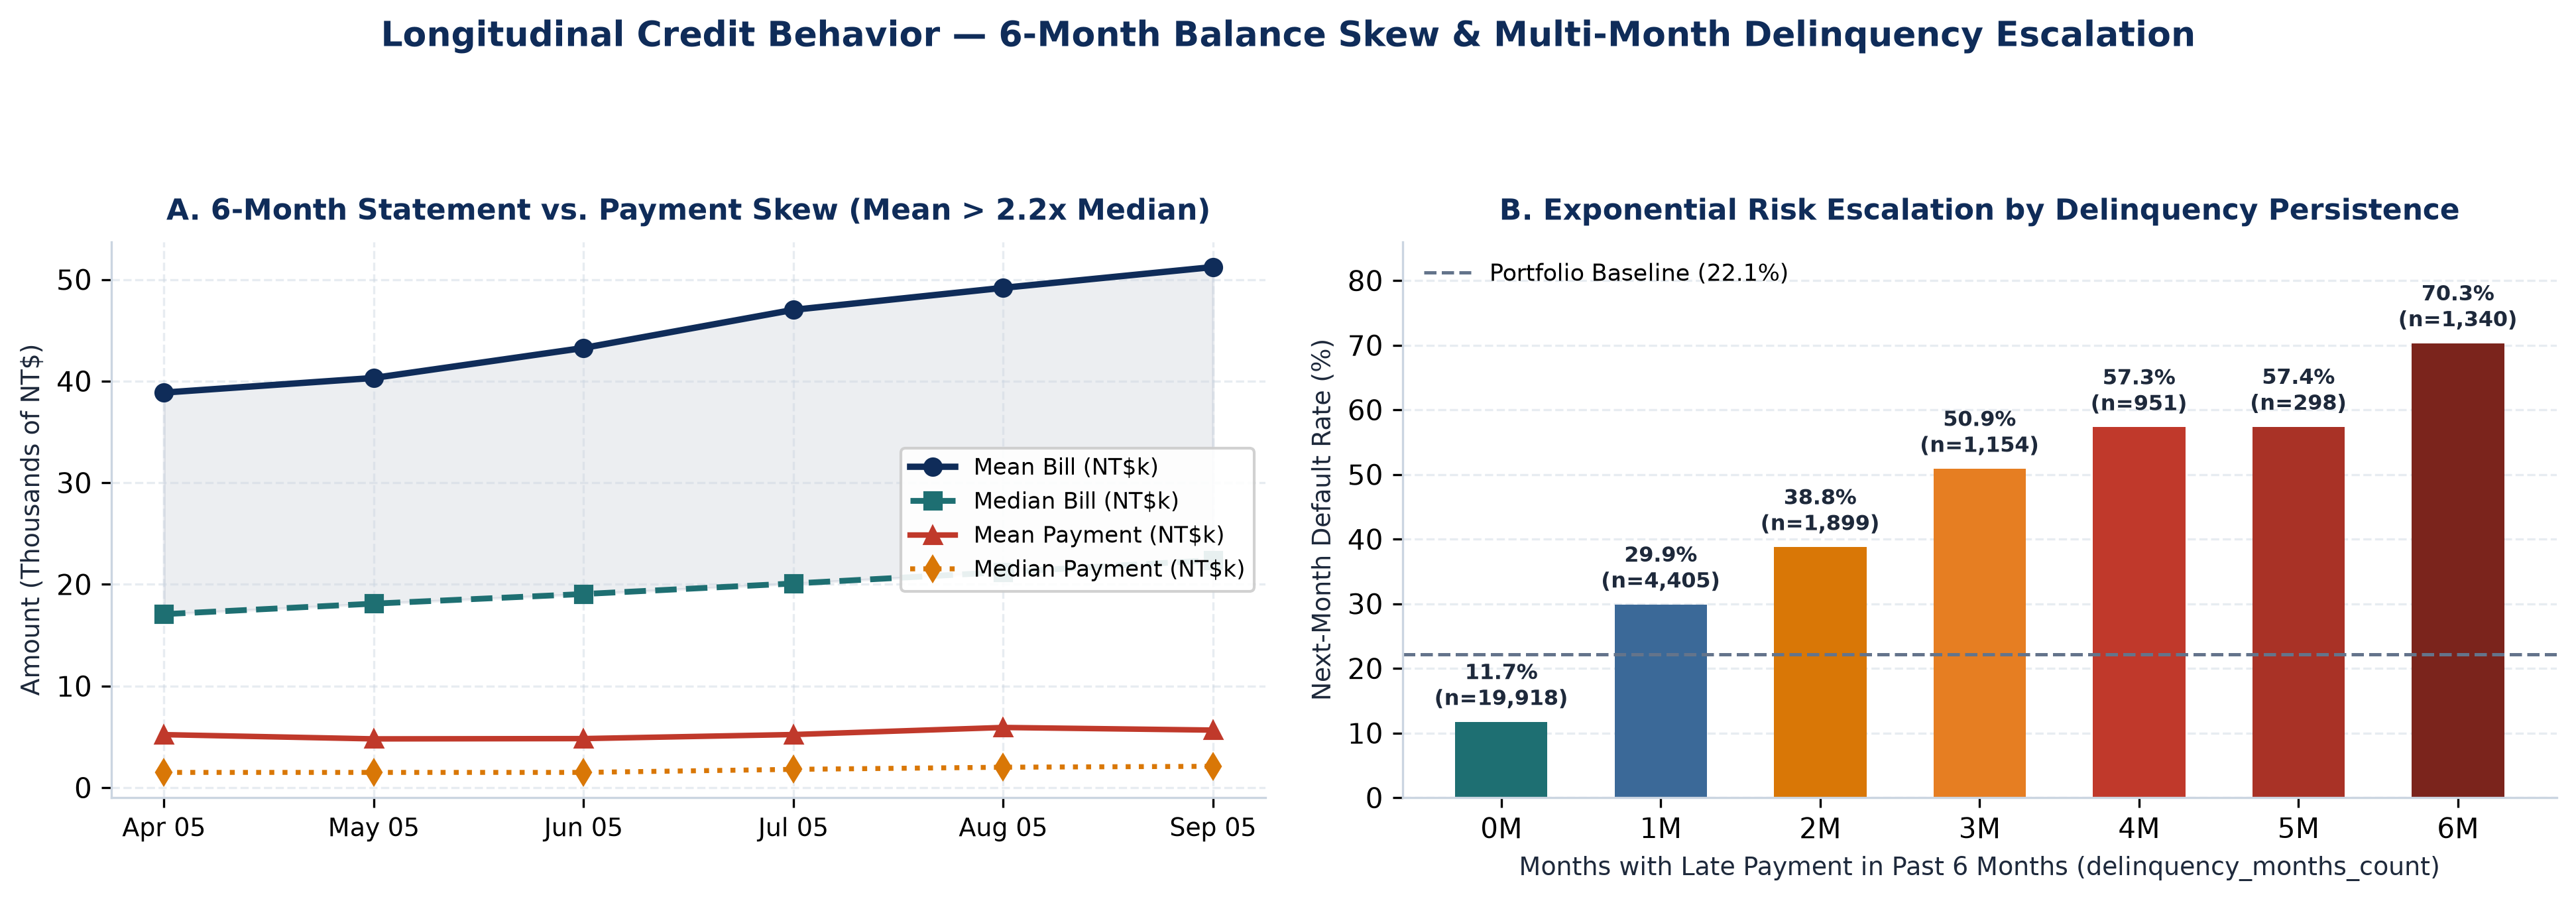

[SAVED] charts/fig02_longitudinal_trajectory.png


In [3]:
# Figure 2: 6-Month Longitudinal Billing Skew & Behavioral Delinquency Escalation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.6), dpi=300)
fig.suptitle("Longitudinal Credit Behavior — 6-Month Balance Skew & Multi-Month Delinquency Escalation",
             fontsize=12.5, fontweight="bold", color=NAVY, y=0.99)

months = ["Apr 05", "May 05", "Jun 05", "Jul 05", "Aug 05", "Sep 05"]
bill_cols_c = ["BILL_AMT6", "BILL_AMT5", "BILL_AMT4", "BILL_AMT3", "BILL_AMT2", "BILL_AMT1"]
pay_cols_c = ["PAY_AMT6", "PAY_AMT5", "PAY_AMT4", "PAY_AMT3", "PAY_AMT2", "PAY_AMT1"]
x = np.arange(len(months))

ax1.plot(x, [raw_df[c].mean()/1000 for c in bill_cols_c], marker="o", linewidth=2.3, color=NAVY, label="Mean Bill (NT$k)")
ax1.plot(x, [raw_df[c].median()/1000 for c in bill_cols_c], marker="s", linewidth=2.1, linestyle="--", color=TEAL, label="Median Bill (NT$k)")
ax1.plot(x, [raw_df[c].mean()/1000 for c in pay_cols_c], marker="^", linewidth=2.0, color=CORAL, label="Mean Payment (NT$k)")
ax1.plot(x, [raw_df[c].median()/1000 for c in pay_cols_c], marker="d", linewidth=1.8, linestyle=":", color=AMBER, label="Median Payment (NT$k)")
ax1.fill_between(x, [raw_df[c].median()/1000 for c in bill_cols_c], [raw_df[c].mean()/1000 for c in bill_cols_c], color=NAVY, alpha=0.08)
ax1.set_xticks(x)
ax1.set_xticklabels(months, fontsize=9.0)
ax1.set_ylabel("Amount (Thousands of NT$)", fontsize=9.2, color=INK)
ax1.set_title("A. 6-Month Statement vs. Payment Skew (Mean > 2.2x Median)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax1.grid(True, linestyle="--", alpha=0.45, color=GRID_COL)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="center right", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.2)

# Panel B: Default Rate by Number of Delinquent Months (0 to 6)
del_grp = df_clean.groupby("delinquency_months_count").agg(n=("default", "count"), rate=("default", "mean")).reset_index()
colors_d = [TEAL, LIGHT_NAVY, AMBER, "#E67E22", CORAL, "#A93226", "#7B241C"]
bars = ax2.bar(del_grp["delinquency_months_count"].astype(str) + "M", del_grp["rate"] * 100, color=colors_d, width=0.58)
ax2.axhline(df_clean["default"].mean() * 100, color=SLATE, linestyle="--", linewidth=1.2, label="Portfolio Baseline (22.1%)")
ax2.set_xlabel("Months with Late Payment in Past 6 Months (delinquency_months_count)", fontsize=9.0, color=INK)
ax2.set_ylabel("Next-Month Default Rate (%)", fontsize=9.2, color=INK)
ax2.set_title("B. Exponential Risk Escalation by Delinquency Persistence", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax2.set_ylim(0, 86)
ax2.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper left", frameon=False, fontsize=8.5)
for b, (_, row) in zip(bars, del_grp.iterrows()):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5,
             f"{row['rate']*100:.1f}%{NL}(n={int(row['n']):,})", ha="center", va="bottom", fontsize=7.8, fontweight="bold", color=INK)

plt.tight_layout(rect=[0, 0, 1, 0.93], pad=1.6)
plt.savefig("charts/fig02_longitudinal_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig02_longitudinal_trajectory.png")


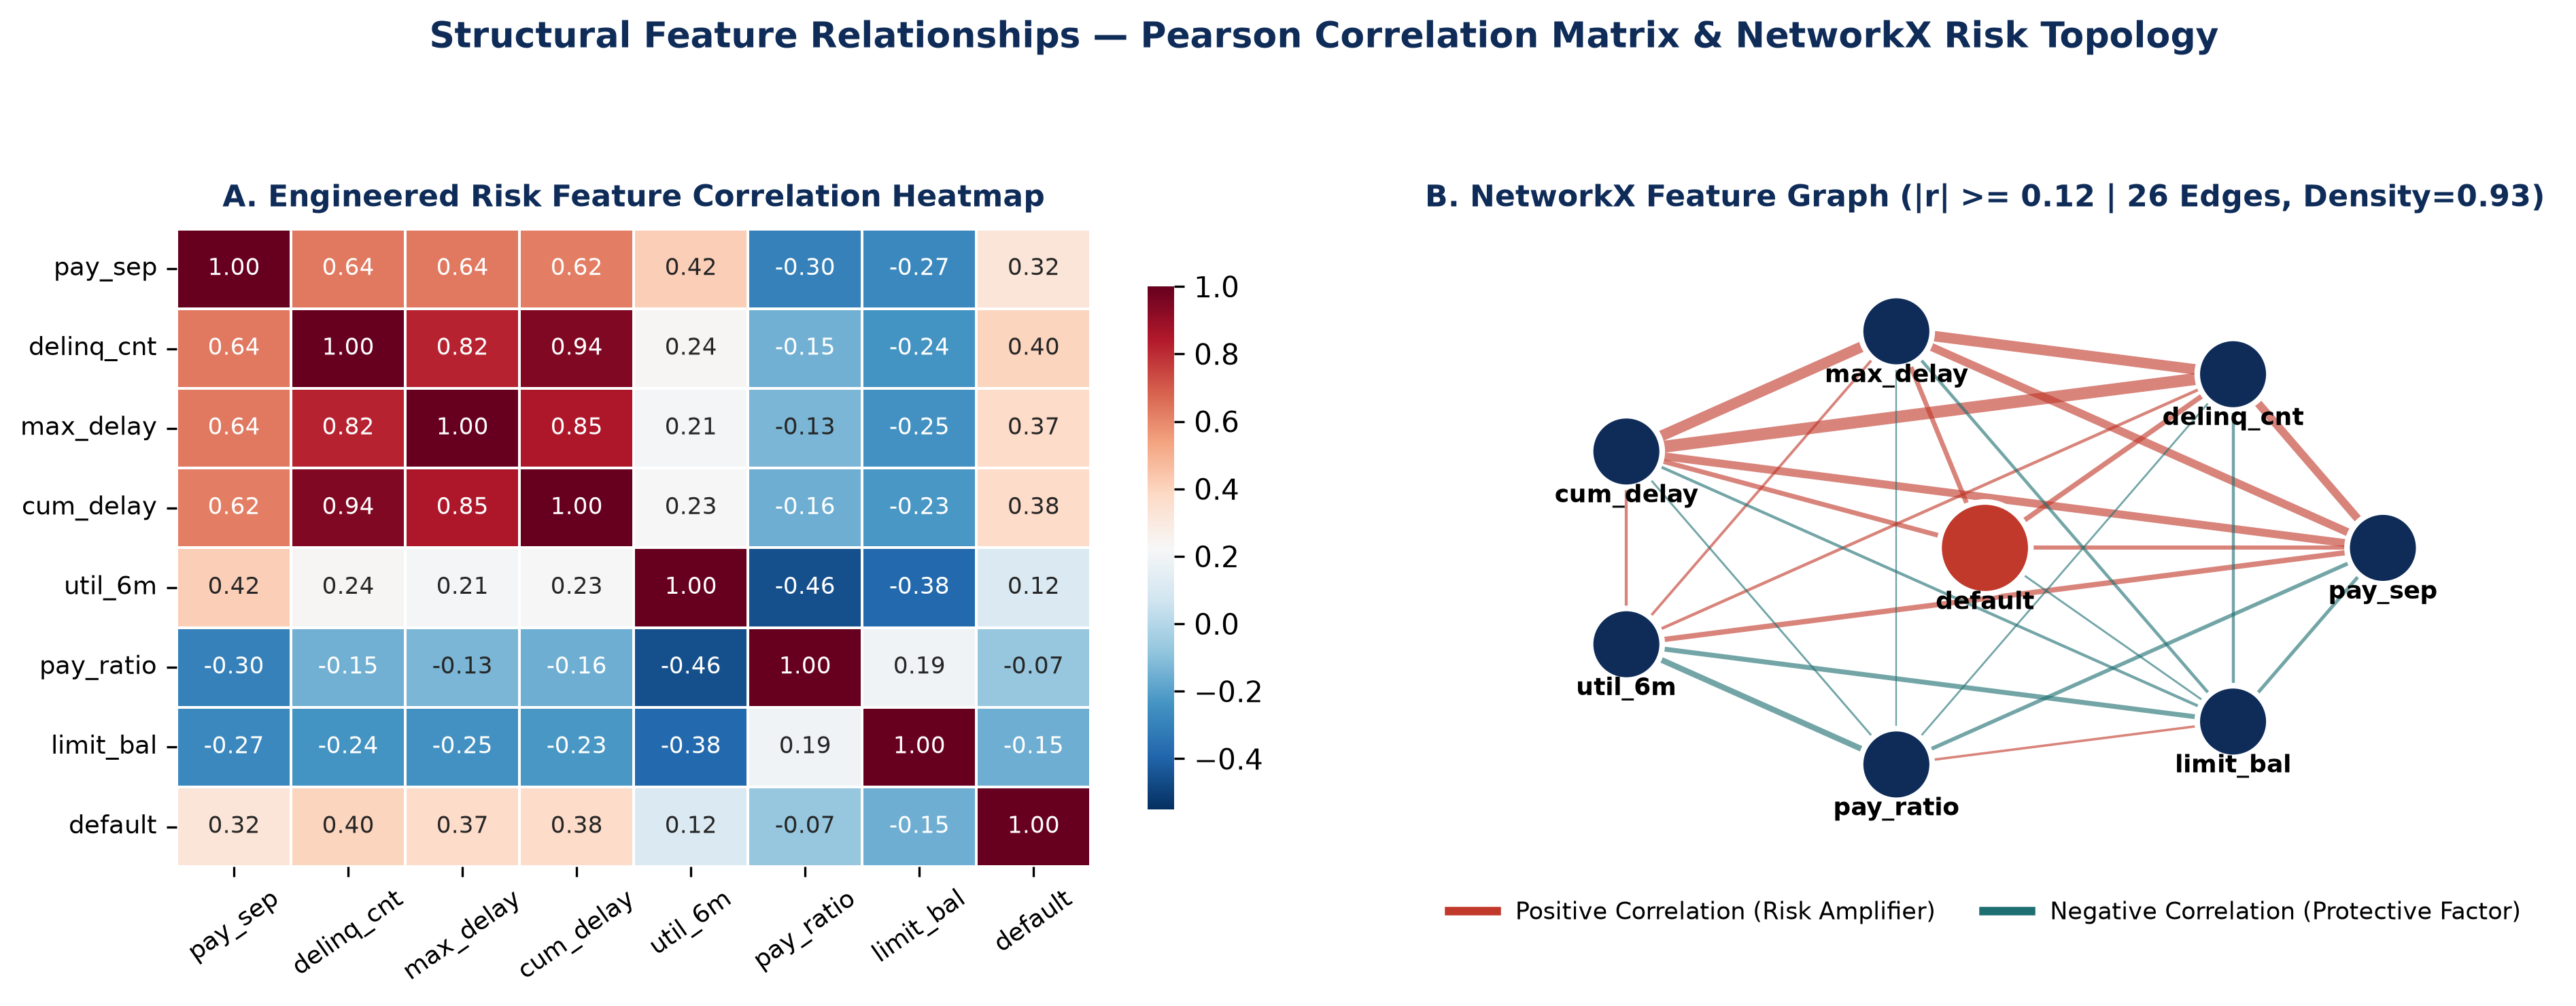

[SAVED] charts/fig03_correlation_and_network.png


In [4]:
# Figure 3: Correlation Matrix Heatmap & NetworkX Credit Risk Feature Graph
top_c_cols = [
    "pay_sep", "delinquency_months_count", "max_delinquency_months",
    "cumulative_delay_score", "avg_utilization_6m", "payment_to_bill_ratio_6m",
    "limit_bal", "default",
]
short_map = {
    "pay_sep": "pay_sep", "delinquency_months_count": "delinq_cnt",
    "max_delinquency_months": "max_delay", "cumulative_delay_score": "cum_delay",
    "avg_utilization_6m": "util_6m", "payment_to_bill_ratio_6m": "pay_ratio",
    "limit_bal": "limit_bal", "default": "default",
}
corr_df = df_clean[top_c_cols].rename(columns=short_map).corr()

G = nx.Graph()
for node in corr_df.columns:
    G.add_node(node)
for i, u in enumerate(corr_df.columns):
    for j, v in enumerate(corr_df.columns):
        if j > i:
            r_val = float(corr_df.loc[u, v])
            if abs(r_val) >= 0.12:
                G.add_edge(u, v, weight=abs(r_val), corr=r_val)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.2), dpi=300)
fig.suptitle("Structural Feature Relationships — Pearson Correlation Matrix & NetworkX Risk Topology",
             fontsize=12.5, fontweight="bold", color=NAVY, y=0.98)

sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.55, vmax=1.0,
            linewidths=0.5, cbar_kws={"shrink": 0.82}, annot_kws={"size": 8.2}, ax=ax1)
ax1.set_title("A. Engineered Risk Feature Correlation Heatmap", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax1.tick_params(axis="x", rotation=35, labelsize=8.8)
ax1.tick_params(axis="y", rotation=0, labelsize=8.8)

other_nodes = [n for n in G.nodes if n != "default"]
angles = np.linspace(0, 2 * np.pi, len(other_nodes), endpoint=False)
pos = {n: (np.cos(angles[idx]) * 0.85, np.sin(angles[idx]) * 0.85) for idx, n in enumerate(other_nodes)}
pos["default"] = (0.0, 0.0)

edges = list(G.edges(data=True))
edge_colors = [CORAL if d["corr"] > 0 else TEAL for _, _, d in edges]
edge_widths = [d["weight"] * 4.5 for _, _, d in edges]
node_colors = [CORAL if n == "default" else NAVY for n in G.nodes]
node_sizes = [1050 if n == "default" else 640 for n in G.nodes]

nx.draw_networkx_edges(G, pos, edgelist=[(u, v) for u, v, _ in edges], edge_color=edge_colors, width=edge_widths, alpha=0.62, ax=ax2)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, edgecolors="white", linewidths=2.0, ax=ax2)
label_pos = {n: (x, y - 0.17 if n != "default" else y - 0.21) for n, (x, y) in pos.items()}
nx.draw_networkx_labels(G, label_pos, font_size=8.6, font_weight="bold", ax=ax2)

# Legend for edge polarity
ax2.plot([], [], color=CORAL, linewidth=3.0, label="Positive Correlation (Risk Amplifier)")
ax2.plot([], [], color=TEAL, linewidth=3.0, label="Negative Correlation (Protective Factor)")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, fontsize=8.4)
ax2.set_title(f"B. NetworkX Feature Graph (|r| >= 0.12 | {G.number_of_edges()} Edges, Density={nx.density(G):.2f})",
              fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax2.set_xlim(-1.22, 1.22)
ax2.set_ylim(-1.22, 1.22)
ax2.axis("off")

plt.tight_layout(rect=[0, 0.03, 1, 0.94], pad=1.5)
plt.savefig("charts/fig03_correlation_and_network.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig03_correlation_and_network.png")


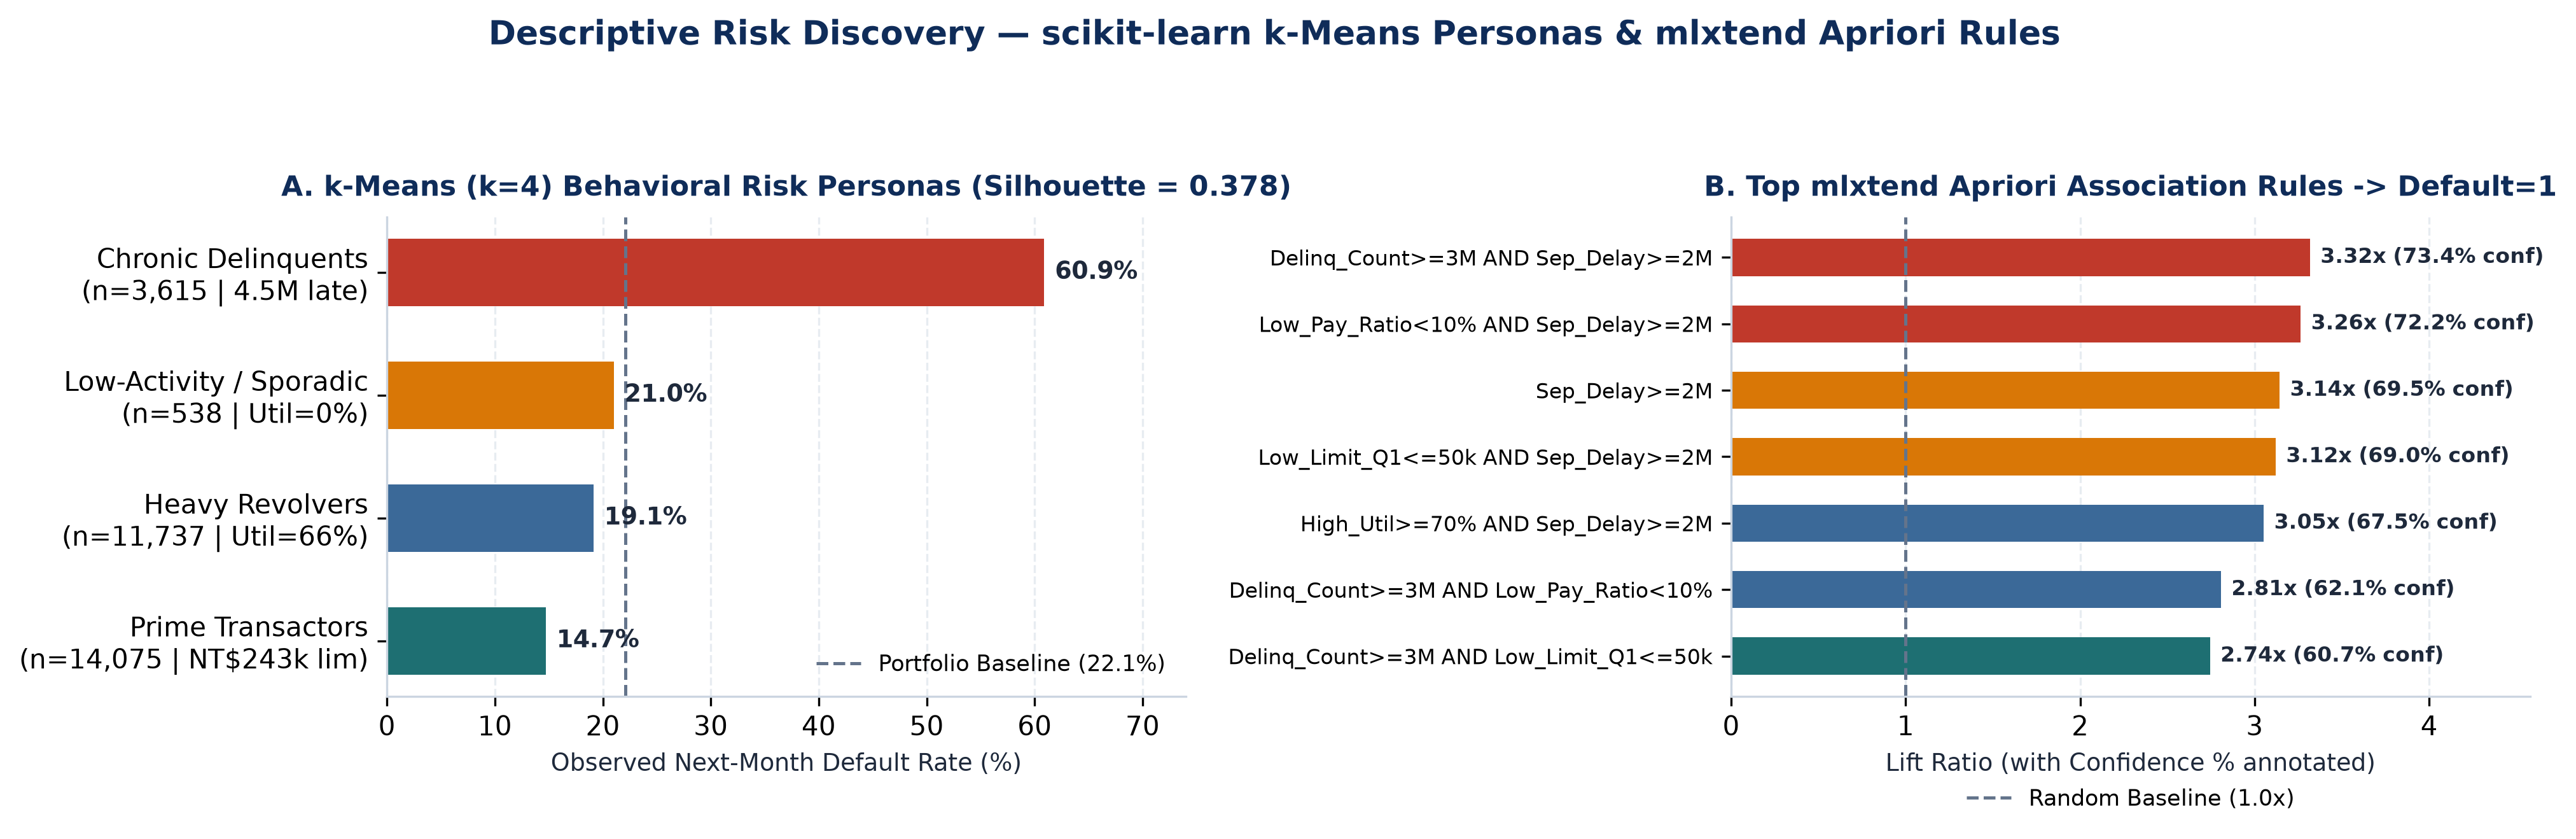

[SAVED] charts/fig04_clustering_and_apriori.png


In [5]:
# Figure 4: Behavioral Risk Segmentation (k-Means k=4) & Top mlxtend Apriori Association Rules
cluster_prof = (
    df_clean.groupby("cluster_k4")
    .agg(Clients=("default", "count"), Default_Rate=("default", "mean"),
         Avg_Limit=("limit_bal", "mean"), Avg_Util=("avg_utilization_6m", "mean"),
         Avg_Delinq=("delinquency_months_count", "mean"))
    .sort_values("Default_Rate", ascending=False)
    .reset_index()
)
persona_names = [
    f"Chronic Delinquents{NL}(n={cluster_prof.loc[0,'Clients']:,} | {cluster_prof.loc[0,'Avg_Delinq']:.1f}M late)",
    f"Low-Activity / Sporadic{NL}(n={cluster_prof.loc[1,'Clients']:,} | Util={cluster_prof.loc[1,'Avg_Util']*100:.0f}%)",
    f"Heavy Revolvers{NL}(n={cluster_prof.loc[2,'Clients']:,} | Util={cluster_prof.loc[2,'Avg_Util']*100:.0f}%)",
    f"Prime Transactors{NL}(n={cluster_prof.loc[3,'Clients']:,} | NT${cluster_prof.loc[3,'Avg_Limit']/1000:.0f}k lim)",
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 4.9), dpi=300)
fig.suptitle("Descriptive Risk Discovery — scikit-learn k-Means Personas & mlxtend Apriori Rules",
             fontsize=12.5, fontweight="bold", color=NAVY, y=0.98)

# Panel A: k=4 Cluster Personas Default Rate
bars = ax1.barh(persona_names[::-1], (cluster_prof["Default_Rate"]*100).iloc[::-1],
                color=[TEAL, LIGHT_NAVY, AMBER, CORAL], height=0.55)
ax1.axvline(22.12, color=SLATE, linestyle="--", linewidth=1.2, label="Portfolio Baseline (22.1%)")
ax1.set_title("A. k-Means (k=4) Behavioral Risk Personas (Silhouette = 0.378)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax1.set_xlabel("Observed Next-Month Default Rate (%)", fontsize=9.0, color=INK)
ax1.set_xlim(0, 74)
ax1.grid(axis="x", linestyle="--", alpha=0.45, color=GRID_COL)
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="lower right", frameon=False, fontsize=8.4)
for b, r in zip(bars, (cluster_prof["Default_Rate"]*100).iloc[::-1]):
    ax1.text(b.get_width() + 1.0, b.get_y() + b.get_height()/2, f"{r:.1f}%", va="center", fontsize=9.0, fontweight="bold", color=INK)

# Panel B: Top 7 mlxtend Apriori Rules -> Default=1
top_rules = assoc_df[assoc_df["Consequent (THEN)"] == "Default_Next_Month=1"].sort_values("Lift", ascending=False).head(7)
r_lbls = top_rules["Antecedent (IF)"].tolist()[::-1]
r_lifts = top_rules["Lift"].tolist()[::-1]
r_confs = top_rules["Confidence"].tolist()[::-1]
bars = ax2.barh(r_lbls, r_lifts, color=[TEAL, LIGHT_NAVY, LIGHT_NAVY, AMBER, AMBER, CORAL, CORAL], height=0.56)
ax2.axvline(1.0, color=SLATE, linestyle="--", linewidth=1.2, label="Random Baseline (1.0x)")
ax2.set_title("B. Top mlxtend Apriori Association Rules -> Default=1", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax2.set_xlabel("Lift Ratio (with Confidence % annotated)", fontsize=9.0, color=INK)
ax2.set_xlim(0, max(r_lifts) * 1.38)
ax2.tick_params(axis="y", labelsize=8.0)
ax2.grid(axis="x", linestyle="--", alpha=0.45, color=GRID_COL)
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, fontsize=8.4)
for b, lv, cv in zip(bars, r_lifts, r_confs):
    ax2.text(b.get_width() + 0.06, b.get_y() + b.get_height()/2, f"{lv:.2f}x ({cv*100:.1f}% conf)",
             va="center", fontsize=8.0, fontweight="bold", color=INK)

plt.tight_layout(rect=[0, 0.04, 1, 0.94], pad=1.6)
plt.savefig("charts/fig04_clustering_and_apriori.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig04_clustering_and_apriori.png")


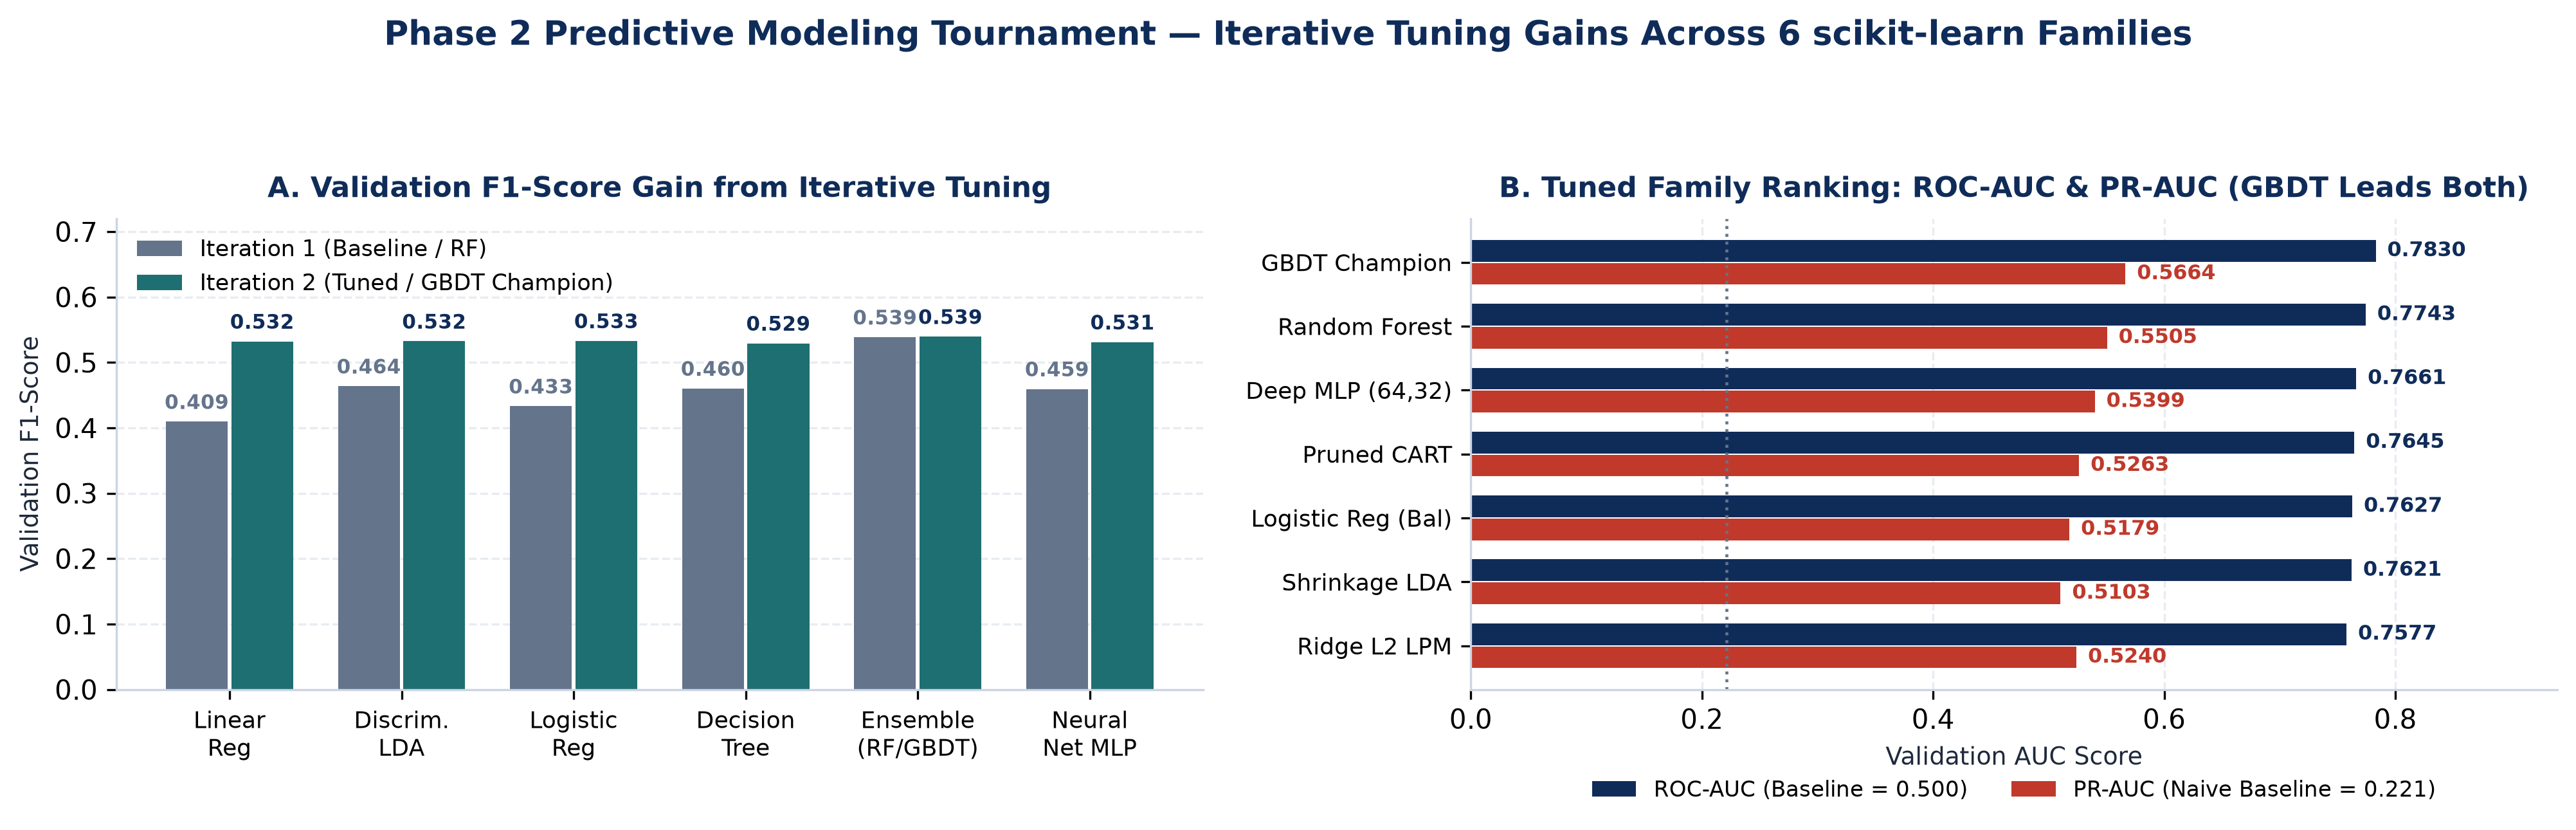

[SAVED] charts/fig05_model_benchmark_and_tuning.png


In [6]:
# Figure 5: Six-Family Predictive Model Benchmark & Iterative Hyperparameter Tuning Gains
exp_idx = exp_df.set_index("Exp_ID")
families = [f"Linear{NL}Reg", f"Discrim.{NL}LDA", f"Logistic{NL}Reg", f"Decision{NL}Tree", f"Ensemble{NL}(RF/GBDT)", f"Neural{NL}Net MLP"]
base_ids = ["EXP-01", "EXP-03", "EXP-05", "EXP-07", "EXP-09", "EXP-11"]
tune_ids = ["EXP-02", "EXP-04", "EXP-06", "EXP-08", "EXP-10", "EXP-12"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 4.8), dpi=300)
fig.suptitle("Phase 2 Predictive Modeling Tournament — Iterative Tuning Gains Across 6 scikit-learn Families",
             fontsize=12.5, fontweight="bold", color=NAVY, y=0.98)

x = np.arange(len(families))
b_f1 = [exp_idx.loc[i, "F1_Score"] for i in base_ids]
t_f1 = [exp_idx.loc[i, "F1_Score"] for i in tune_ids]

bars1 = ax1.bar(x - 0.19, b_f1, width=0.36, color=SLATE, label="Iteration 1 (Baseline / RF)")
bars2 = ax1.bar(x + 0.19, t_f1, width=0.36, color=TEAL, label="Iteration 2 (Tuned / GBDT Champion)")
ax1.set_xticks(x)
ax1.set_xticklabels(families, fontsize=8.6)
ax1.set_ylabel("Validation F1-Score", fontsize=9.2, color=INK)
ax1.set_ylim(0, 0.72)
ax1.set_title("A. Validation F1-Score Gain from Iterative Tuning", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax1.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="upper left", frameon=False, fontsize=8.4)
for b in bars1:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.012, f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=7.4, color=SLATE, fontweight="bold")
for b in bars2:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.012, f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=7.4, color=NAVY, fontweight="bold")

# Panel B: Tuned Model Ranking by ROC-AUC & PR-AUC
ranked_ids = ["EXP-10", "EXP-09", "EXP-12", "EXP-08", "EXP-06", "EXP-04", "EXP-02"]
r_names = ["GBDT Champion", "Random Forest", "Deep MLP (64,32)", "Pruned CART", "Logistic Reg (Bal)", "Shrinkage LDA", "Ridge L2 LPM"][::-1]
r_roc = [exp_idx.loc[i, "ROC_AUC"] for i in ranked_ids][::-1]
r_pr = [exp_idx.loc[i, "PR_AUC"] for i in ranked_ids][::-1]
y_pos = np.arange(len(r_names))

ax2.barh(y_pos + 0.18, r_roc, height=0.34, color=NAVY, label="ROC-AUC (Baseline = 0.500)")
ax2.barh(y_pos - 0.18, r_pr, height=0.34, color=CORAL, label="PR-AUC (Naive Baseline = 0.221)")
ax2.axvline(0.2212, color=SLATE, linestyle=":", linewidth=1.1)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(r_names, fontsize=8.6)
ax2.set_xlabel("Validation AUC Score", fontsize=9.2, color=INK)
ax2.set_xlim(0, 0.94)
ax2.set_title("B. Tuned Family Ranking: ROC-AUC & PR-AUC (GBDT Leads Both)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax2.grid(axis="x", linestyle="--", alpha=0.45, color=GRID_COL)
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=8.2)
for idx_y, (rv, pv) in enumerate(zip(r_roc, r_pr)):
    ax2.text(rv + 0.01, idx_y + 0.18, f"{rv:.4f}", va="center", fontsize=7.8, fontweight="bold", color=NAVY)
    ax2.text(pv + 0.01, idx_y - 0.18, f"{pv:.4f}", va="center", fontsize=7.8, fontweight="bold", color=CORAL)

plt.tight_layout(rect=[0, 0.04, 1, 0.94], pad=1.6)
plt.savefig("charts/fig05_model_benchmark_and_tuning.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig05_model_benchmark_and_tuning.png")


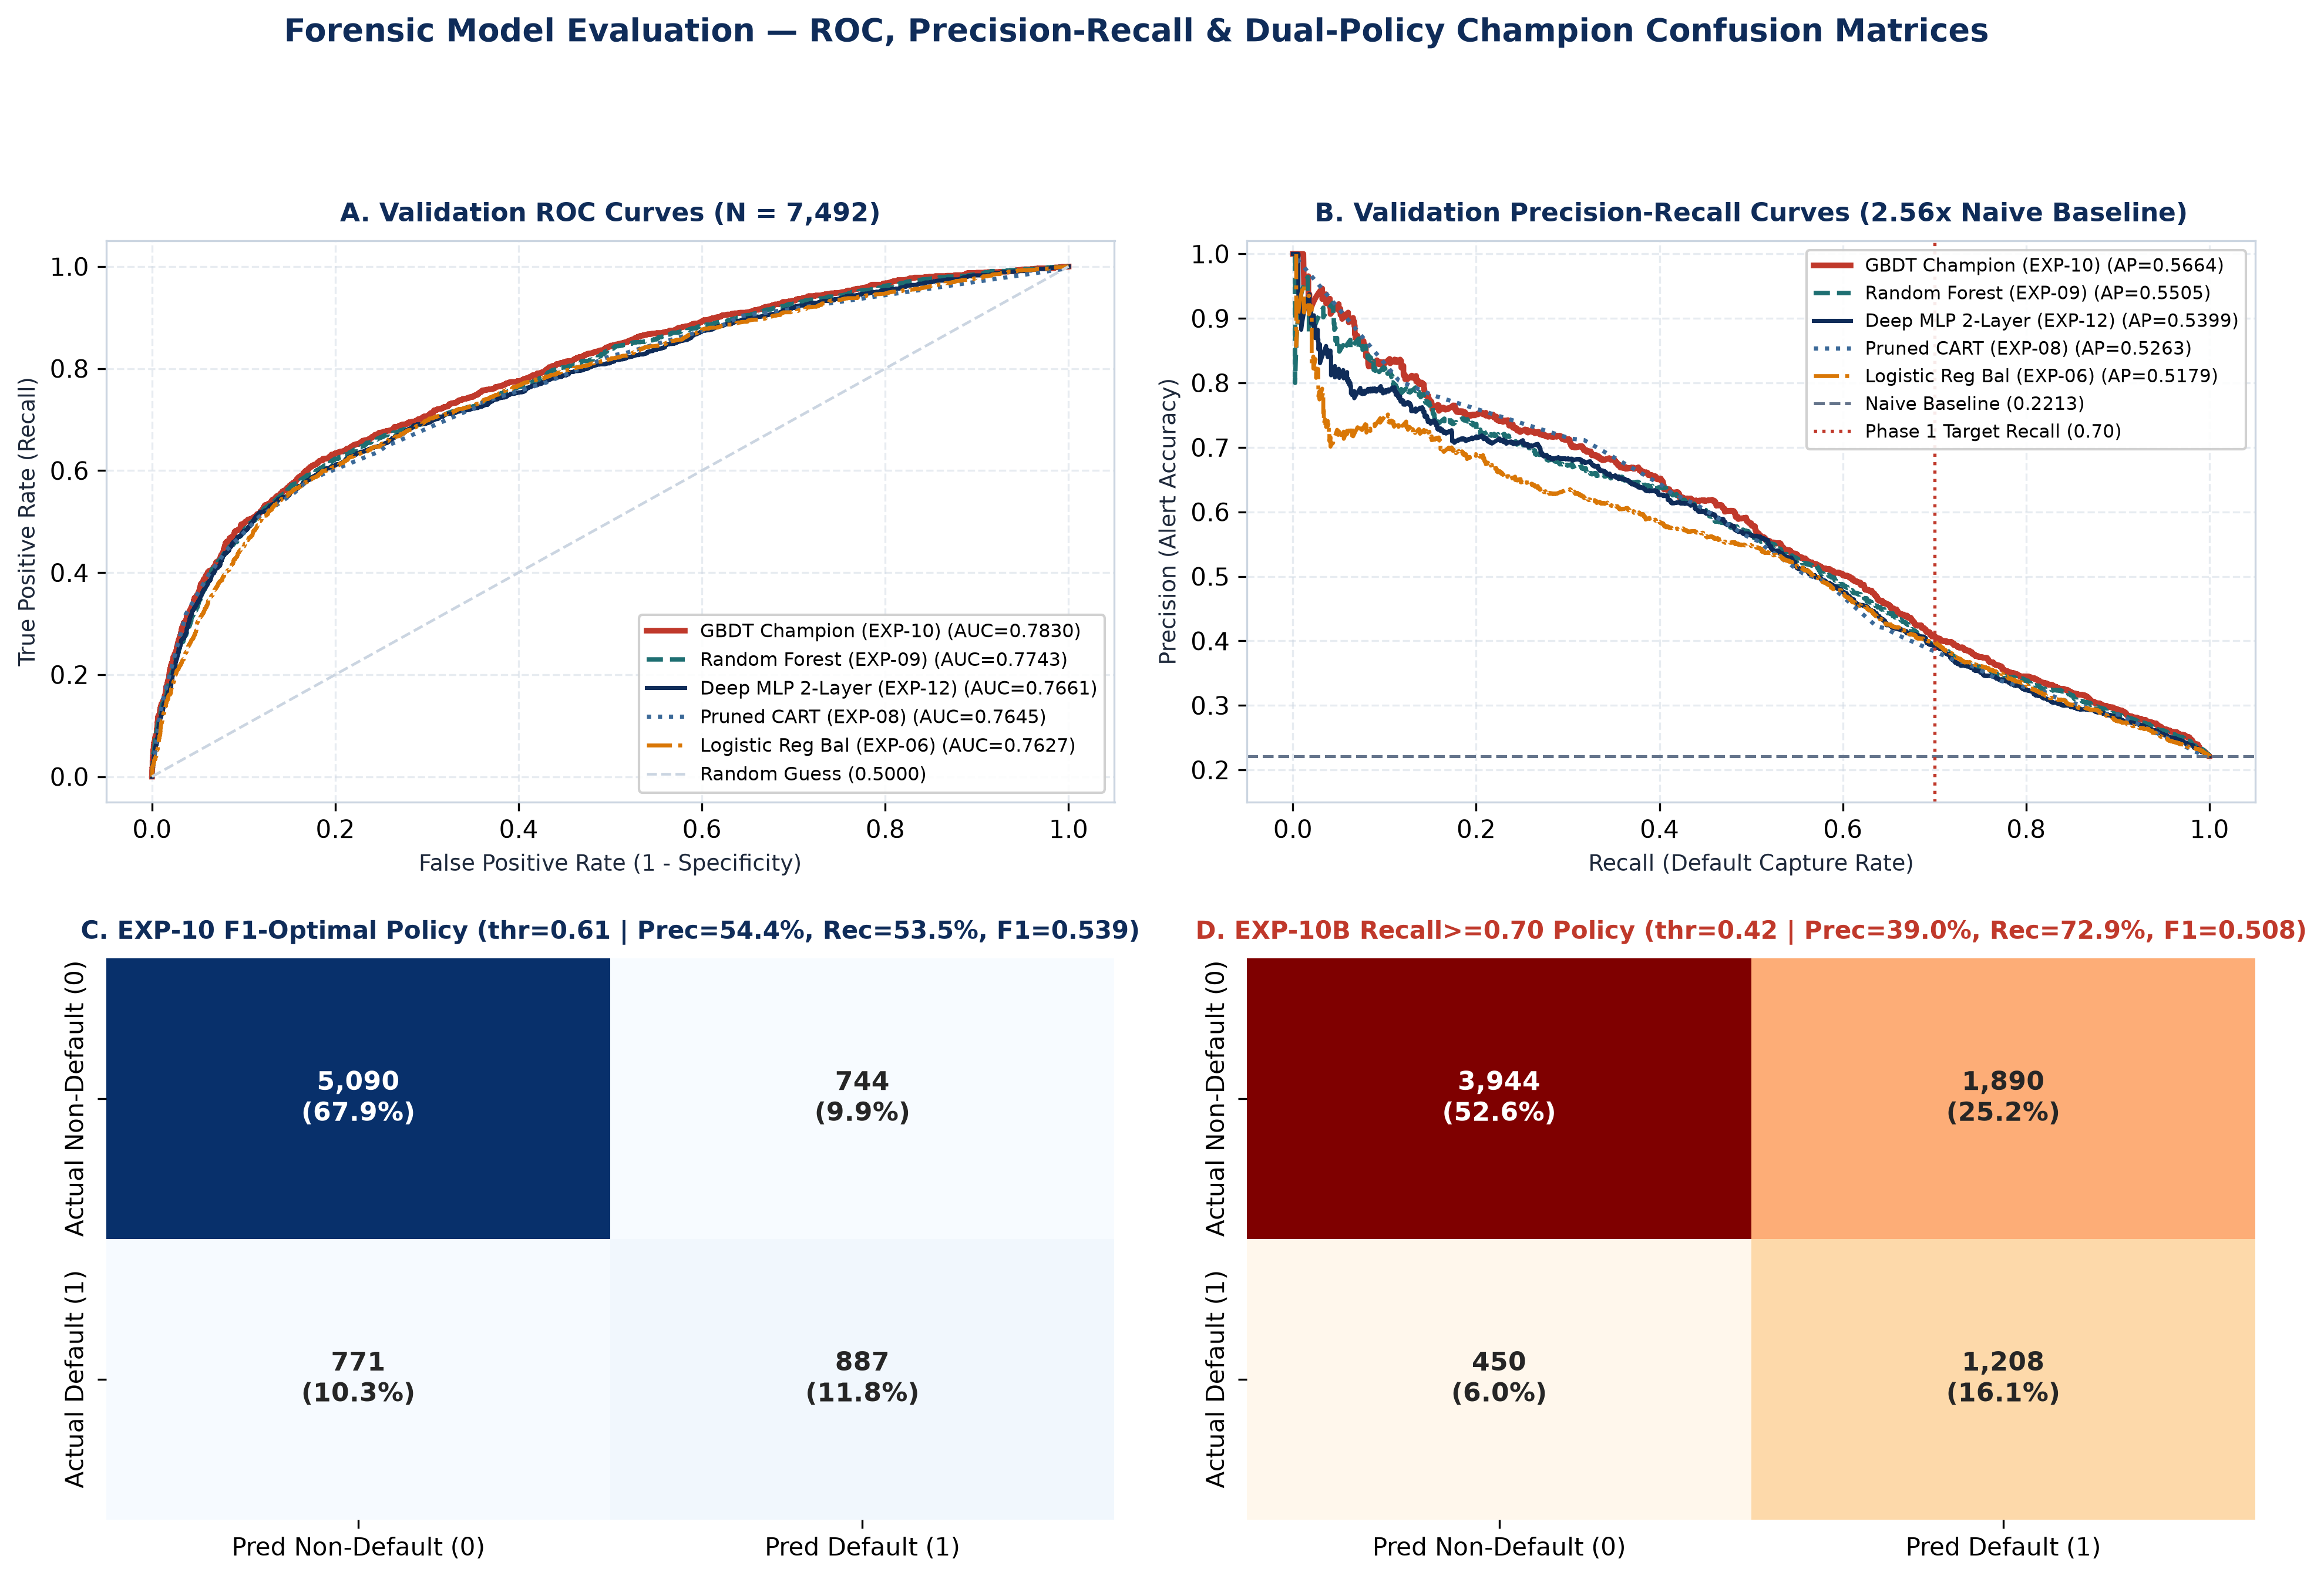

[SAVED] charts/fig06_roc_pr_and_confusion_matrices.png


In [7]:
# Figure 6: Forensic Evaluation Panel — ROC Curves, Precision-Recall Curves & Dual-Policy Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(13.2, 9.2), dpi=300)
fig.suptitle("Forensic Model Evaluation — ROC, Precision-Recall & Dual-Policy Champion Confusion Matrices",
             fontsize=13.0, fontweight="bold", color=NAVY, y=0.98)

model_curves = [
    ("GBDT Champion (EXP-10)", p_gb, CORAL, "-", 2.3),
    ("Random Forest (EXP-09)", p_rf, TEAL, "--", 1.8),
    ("Deep MLP 2-Layer (EXP-12)", p_mlp, NAVY, "-", 1.7),
    ("Pruned CART (EXP-08)", p_dt, LIGHT_NAVY, ":", 1.7),
    ("Logistic Reg Bal (EXP-06)", p_lr, AMBER, "-.", 1.6),
]

# Panel A: ROC Curves
ax = axes[0, 0]
for name, prob, col, ls, lw in model_curves:
    fpr, tpr, _ = roc_curve(y_val, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_val, prob):.4f})", color=col, linestyle=ls, linewidth=lw)
ax.plot([0, 1], [0, 1], color=GRID_COL, linestyle="--", linewidth=1.1, label="Random Guess (0.5000)")
ax.set_title("A. Validation ROC Curves (N = 7,492)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=9.0, color=INK)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=9.0, color=INK)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9, fontsize=7.8)
ax.grid(True, linestyle="--", alpha=0.45, color=GRID_COL)

# Panel B: Precision-Recall Curves
ax = axes[0, 1]
for name, prob, col, ls, lw in model_curves:
    prec, rec, _ = precision_recall_curve(y_val, prob)
    ax.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_val, prob):.4f})", color=col, linestyle=ls, linewidth=lw)
ax.axhline(y_val.mean(), color=SLATE, linestyle="--", linewidth=1.2, label=f"Naive Baseline ({y_val.mean():.4f})")
ax.axvline(0.70, color=CORAL, linestyle=":", linewidth=1.3, label="Phase 1 Target Recall (0.70)")
ax.set_title("B. Validation Precision-Recall Curves (2.56x Naive Baseline)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax.set_xlabel("Recall (Default Capture Rate)", fontsize=9.0, color=INK)
ax.set_ylabel("Precision (Alert Accuracy)", fontsize=9.0, color=INK)
ax.set_ylim(0.15, 1.02)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9, fontsize=7.5)
ax.grid(True, linestyle="--", alpha=0.45, color=GRID_COL)

# Panel C: EXP-10 F1-Optimal Confusion Matrix (thr = 0.61)
ax = axes[1, 0]
pred_f1 = (p_gb >= thr_f1).astype(int)
cm_f1 = confusion_matrix(y_val, pred_f1)
cm_f1_pct = cm_f1 / cm_f1.sum() * 100
annot_f1 = np.array([[f"{cm_f1[i,j]:,}{NL}({cm_f1_pct[i,j]:.1f}%)" for j in range(2)] for i in range(2)])
sns.heatmap(cm_f1, annot=annot_f1, fmt="", cmap="Blues", cbar=False, annot_kws={"size": 10.5, "weight": "bold"},
            xticklabels=["Pred Non-Default (0)", "Pred Default (1)"],
            yticklabels=["Actual Non-Default (0)", "Actual Default (1)"], ax=ax)
ax.set_title(f"C. EXP-10 F1-Optimal Policy (thr={thr_f1} | Prec=54.4%, Rec=53.5%, F1=0.539)",
             fontsize=10.0, fontweight="bold", color=NAVY, pad=8)

# Panel D: EXP-10B Recall>=0.70 Loss-Prevention Confusion Matrix (thr = 0.42)
ax = axes[1, 1]
pred_r70 = (p_gb >= thr_rec70).astype(int)
cm_r70 = confusion_matrix(y_val, pred_r70)
cm_r70_pct = cm_r70 / cm_r70.sum() * 100
annot_r70 = np.array([[f"{cm_r70[i,j]:,}{NL}({cm_r70_pct[i,j]:.1f}%)" for j in range(2)] for i in range(2)])
sns.heatmap(cm_r70, annot=annot_r70, fmt="", cmap="OrRd", cbar=False, annot_kws={"size": 10.5, "weight": "bold"},
            xticklabels=["Pred Non-Default (0)", "Pred Default (1)"],
            yticklabels=["Actual Non-Default (0)", "Actual Default (1)"], ax=ax)
ax.set_title(f"D. EXP-10B Recall>=0.70 Policy (thr={thr_rec70} | Prec=39.0%, Rec=72.9%, F1=0.508)",
             fontsize=10.0, fontweight="bold", color=CORAL, pad=8)

plt.tight_layout(rect=[0, 0, 1, 0.94], pad=1.8)
plt.savefig("charts/fig06_roc_pr_and_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig06_roc_pr_and_confusion_matrices.png")


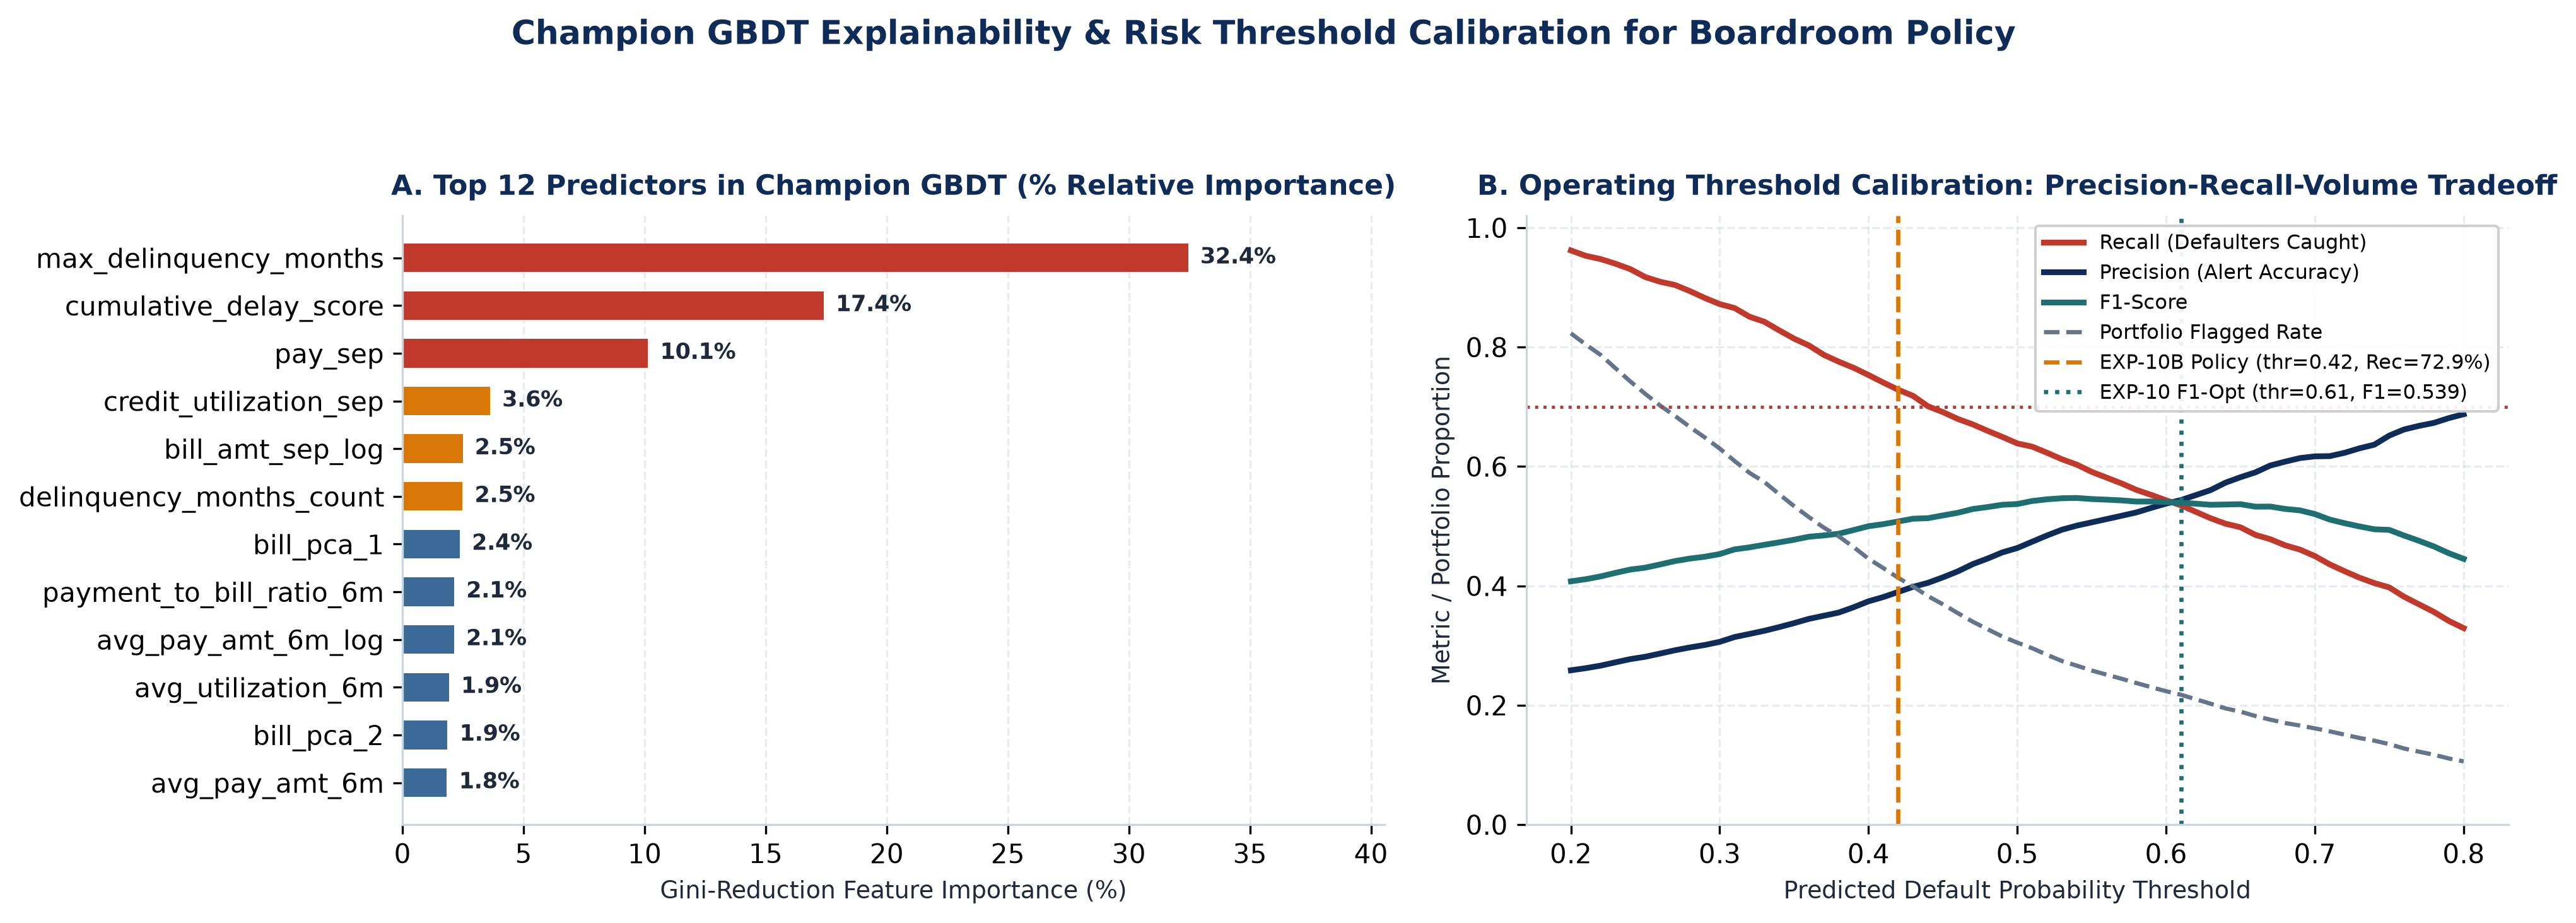

[SAVED] charts/fig07_feature_importance_and_threshold_roi.png


In [8]:
# Figure 7: Champion Model Explainability (Feature Importance) & Decision Threshold Tradeoff Curve
importances = pd.Series(gb_model.feature_importances_, index=feature_names).sort_values(ascending=False)
top12_imp = importances.head(12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.0), dpi=300)
fig.suptitle("Champion GBDT Explainability & Risk Threshold Calibration for Boardroom Policy",
             fontsize=12.5, fontweight="bold", color=NAVY, y=0.98)

# Panel A: Top 12 Feature Importances
cols_imp = [CORAL if i < 3 else (AMBER if i < 6 else LIGHT_NAVY) for i in range(12)][::-1]
bars = ax1.barh(top12_imp.index[::-1], top12_imp.values[::-1] * 100, color=cols_imp, height=0.60)
ax1.set_title("A. Top 12 Predictors in Champion GBDT (% Relative Importance)", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax1.set_xlabel("Gini-Reduction Feature Importance (%)", fontsize=9.0, color=INK)
ax1.set_xlim(0, top12_imp.max() * 125)
ax1.grid(axis="x", linestyle="--", alpha=0.45, color=GRID_COL)
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
for b, val in zip(bars, top12_imp.values[::-1] * 100):
    ax1.text(b.get_width() + 0.5, b.get_y() + b.get_height()/2, f"{val:.1f}%", va="center", fontsize=8.3, fontweight="bold", color=INK)

# Panel B: Threshold Tradeoff Curve (Recall, Precision, F1, % Flagged)
thrs = np.linspace(0.20, 0.80, 61)
rec_s = [recall_score(y_val, (p_gb >= t).astype(int), zero_division=0) for t in thrs]
pre_s = [precision_score(y_val, (p_gb >= t).astype(int), zero_division=0) for t in thrs]
f1_s = [f1_score(y_val, (p_gb >= t).astype(int), zero_division=0) for t in thrs]
flg_s = [np.mean(p_gb >= t) for t in thrs]

ax2.plot(thrs, rec_s, color=CORAL, linewidth=2.2, label="Recall (Defaulters Caught)")
ax2.plot(thrs, pre_s, color=NAVY, linewidth=2.2, label="Precision (Alert Accuracy)")
ax2.plot(thrs, f1_s, color=TEAL, linewidth=2.2, label="F1-Score")
ax2.plot(thrs, flg_s, color=SLATE, linewidth=1.6, linestyle="--", label="Portfolio Flagged Rate")
ax2.axhline(0.70, color=CORAL, linestyle=":", linewidth=1.2)
ax2.axvline(thr_rec70, color=AMBER, linestyle="--", linewidth=1.6, label=f"EXP-10B Policy (thr={thr_rec70}, Rec=72.9%)")
ax2.axvline(thr_f1, color=TEAL, linestyle=":", linewidth=1.6, label=f"EXP-10 F1-Opt (thr={thr_f1}, F1=0.539)")
ax2.set_title("B. Operating Threshold Calibration: Precision-Recall-Volume Tradeoff", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax2.set_xlabel("Predicted Default Probability Threshold", fontsize=9.0, color=INK)
ax2.set_ylabel("Metric / Portfolio Proportion", fontsize=9.0, color=INK)
ax2.set_ylim(0, 1.02)
ax2.grid(True, linestyle="--", alpha=0.45, color=GRID_COL)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=7.6)

plt.tight_layout(rect=[0, 0, 1, 0.94], pad=1.6)
plt.savefig("charts/fig07_feature_importance_and_threshold_roi.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig07_feature_importance_and_threshold_roi.png")


=== FORENSIC FAIRNESS AUDIT (GBDT EXP-10B Policy, thr=0.42) ===
--- By Biological Sex ---
 Group    N  Base_Default_Rate  Flag_Rate  TPR_Recall    FPR  ROC_AUC
Female 4554             0.2079     0.3878      0.7181 0.3011   0.7923
  Male 2938             0.2420     0.4534      0.7426 0.3610   0.7675

--- By Education Tier ---
      Group    N  Base_Default_Rate  Flag_Rate  TPR_Recall    FPR  ROC_AUC
   Graduate 2620             0.1805     0.3527      0.6702 0.2827   0.7644
 University 3541             0.2389     0.4411      0.7494 0.3443   0.7879
High School 1293             0.2606     0.4695      0.7626 0.3661   0.7822


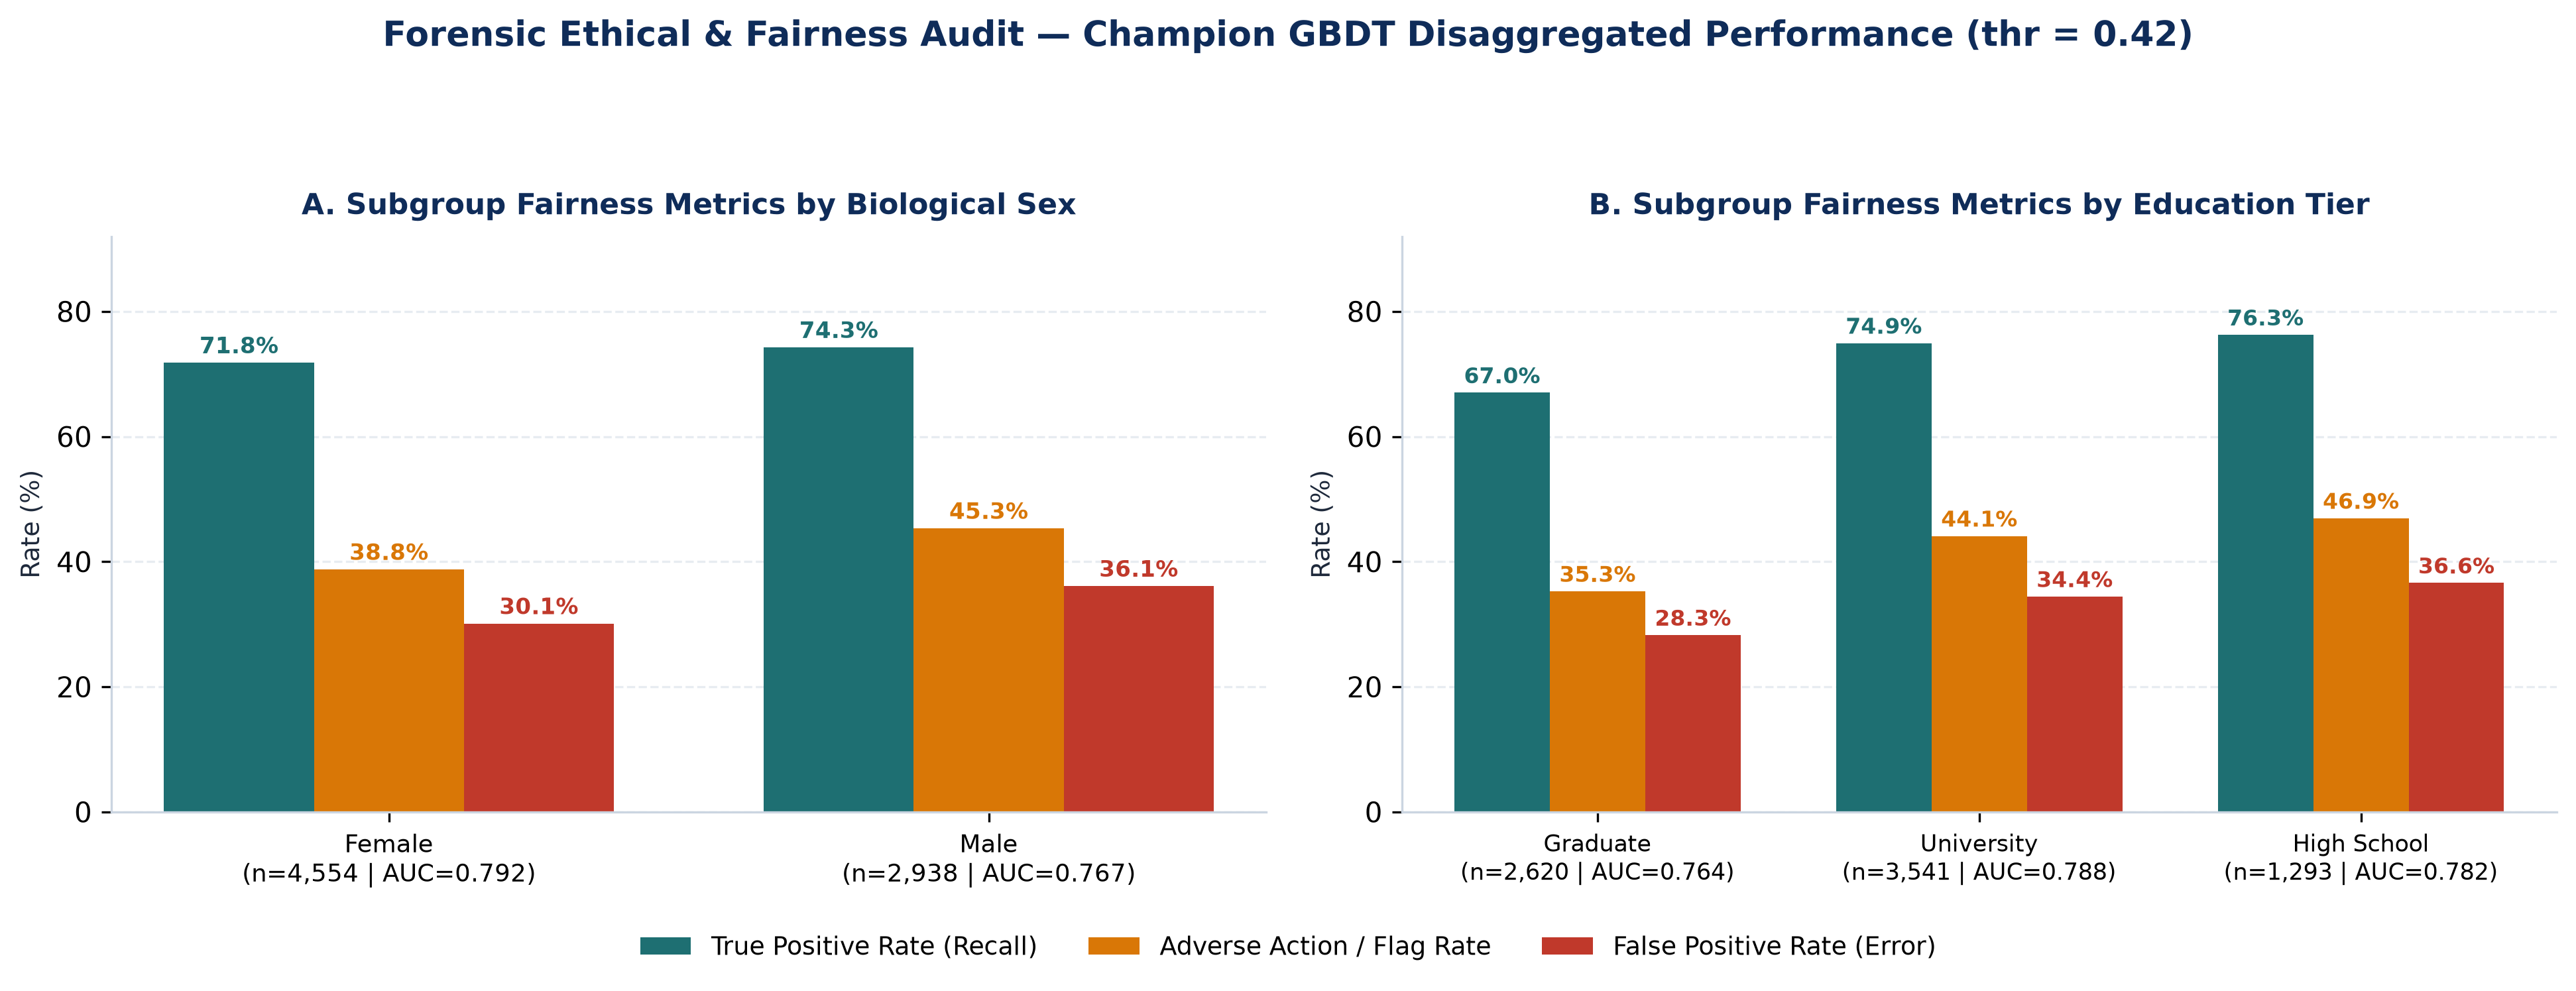

[SAVED] charts/fig08_fairness_and_bias_audit.png
[SUCCESS] Saved phase3_metrics_summary.json and all 8 high-resolution charts!


In [9]:
# Figure 8: Forensic Fairness & Ethical Bias Audit Across Protected / Sensitive Subgroups
# Reconstruct demographic subgroups on Validation set directly from one-hot columns
sex_grp = np.where(val_df["sex_male"] == 1, "Male", "Female")
edu_grp = np.select(
    [val_df["education_university"] == 1, val_df["education_high_school"] == 1, val_df["education_others"] == 1],
    ["University", "High School", "Others"],
    default="Graduate",
)

def subgroup_audit(groups, labels_order, probs, threshold):
    rows = []
    preds = (probs >= threshold).astype(int)
    for g in labels_order:
        m = groups == g
        yt, yp, pr = y_val[m], preds[m], probs[m]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        tpr = tp / max(tp + fn, 1)
        fpr = fp / max(fp + tn, 1)
        flag_rate = float(yp.mean())
        auc = float(roc_auc_score(yt, pr)) if len(np.unique(yt)) == 2 else np.nan
        rows.append({
            "Group": g, "N": int(m.sum()), "Base_Default_Rate": round(float(yt.mean()), 4),
            "Flag_Rate": round(flag_rate, 4), "TPR_Recall": round(float(tpr), 4),
            "FPR": round(float(fpr), 4), "ROC_AUC": round(auc, 4),
        })
    return pd.DataFrame(rows)

sex_audit = subgroup_audit(sex_grp, ["Female", "Male"], p_gb, thr_rec70)
edu_audit = subgroup_audit(edu_grp, ["Graduate", "University", "High School"], p_gb, thr_rec70)

print("=== FORENSIC FAIRNESS AUDIT (GBDT EXP-10B Policy, thr=0.42) ===")
print("--- By Biological Sex ---")
print(sex_audit.to_string(index=False))
print("\n--- By Education Tier ---")
print(edu_audit.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0), dpi=300)
fig.suptitle(f"Forensic Ethical & Fairness Audit — Champion GBDT Disaggregated Performance (thr = {thr_rec70})",
             fontsize=12.5, fontweight="bold", color=NAVY, y=0.98)

# Panel A: By Sex
x_s = np.arange(len(sex_audit))
w = 0.25
b_t = ax1.bar(x_s - w, sex_audit["TPR_Recall"]*100, width=w, color=TEAL, label="True Positive Rate (Recall)")
b_f = ax1.bar(x_s, sex_audit["Flag_Rate"]*100, width=w, color=AMBER, label="Adverse Action / Flag Rate")
b_e = ax1.bar(x_s + w, sex_audit["FPR"]*100, width=w, color=CORAL, label="False Positive Rate (Error)")
ax1.set_xticks(x_s)
ax1.set_xticklabels([f"{r['Group']}{NL}(n={r['N']:,} | AUC={r['ROC_AUC']:.3f})" for _, r in sex_audit.iterrows()], fontsize=8.8)
ax1.set_ylabel("Rate (%)", fontsize=9.2, color=INK)
ax1.set_ylim(0, 92)
ax1.set_title("A. Subgroup Fairness Metrics by Biological Sex", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax1.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
for idx_i, r in sex_audit.iterrows():
    ax1.text(idx_i - w, r["TPR_Recall"]*100 + 1.5, f"{r['TPR_Recall']*100:.1f}%", ha="center", fontsize=8.2, fontweight="bold", color=TEAL)
    ax1.text(idx_i, r["Flag_Rate"]*100 + 1.5, f"{r['Flag_Rate']*100:.1f}%", ha="center", fontsize=8.2, fontweight="bold", color=AMBER)
    ax1.text(idx_i + w, r["FPR"]*100 + 1.5, f"{r['FPR']*100:.1f}%", ha="center", fontsize=8.2, fontweight="bold", color=CORAL)

# Panel B: By Education
x_e = np.arange(len(edu_audit))
ax2.bar(x_e - w, edu_audit["TPR_Recall"]*100, width=w, color=TEAL)
ax2.bar(x_e, edu_audit["Flag_Rate"]*100, width=w, color=AMBER)
ax2.bar(x_e + w, edu_audit["FPR"]*100, width=w, color=CORAL)
ax2.set_xticks(x_e)
ax2.set_xticklabels([f"{r['Group']}{NL}(n={r['N']:,} | AUC={r['ROC_AUC']:.3f})" for _, r in edu_audit.iterrows()], fontsize=8.5)
ax2.set_ylabel("Rate (%)", fontsize=9.2, color=INK)
ax2.set_ylim(0, 92)
ax2.set_title("B. Subgroup Fairness Metrics by Education Tier", fontsize=10.5, fontweight="bold", color=NAVY, pad=8)
ax2.grid(axis="y", linestyle="--", alpha=0.45, color=GRID_COL)
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
for idx_i, r in edu_audit.iterrows():
    ax2.text(idx_i - w, r["TPR_Recall"]*100 + 1.5, f"{r['TPR_Recall']*100:.1f}%", ha="center", fontsize=8.0, fontweight="bold", color=TEAL)
    ax2.text(idx_i, r["Flag_Rate"]*100 + 1.5, f"{r['Flag_Rate']*100:.1f}%", ha="center", fontsize=8.0, fontweight="bold", color=AMBER)
    ax2.text(idx_i + w, r["FPR"]*100 + 1.5, f"{r['FPR']*100:.1f}%", ha="center", fontsize=8.0, fontweight="bold", color=CORAL)

fig.legend([b_t, b_f, b_e], ["True Positive Rate (Recall)", "Adverse Action / Flag Rate", "False Positive Rate (Error)"],
           loc="lower center", bbox_to_anchor=(0.5, 0.01), ncol=3, frameon=False, fontsize=9.2)
plt.tight_layout(rect=[0, 0.06, 1, 0.93], pad=1.6)
plt.savefig("charts/fig08_fairness_and_bias_audit.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SAVED] charts/fig08_fairness_and_bias_audit.png")

# Save verified Phase 3 metrics JSON for programmatic Report & Pitch Deck generation
cm_f1_vals = confusion_matrix(y_val, (p_gb >= thr_f1).astype(int)).ravel().tolist()
cm_r70_vals = confusion_matrix(y_val, (p_gb >= thr_rec70).astype(int)).ravel().tolist()
summary = {
    "champion_model": "GradientBoostingClassifier (EXP-10 / EXP-10B)",
    "roc_auc": round(float(roc_auc_score(y_val, p_gb)), 4),
    "pr_auc": round(float(average_precision_score(y_val, p_gb)), 4),
    "exp10_f1_opt": {
        "threshold": thr_f1,
        "tn": cm_f1_vals[0], "fp": cm_f1_vals[1], "fn": cm_f1_vals[2], "tp": cm_f1_vals[3],
        "flagged_pct": round(float(np.mean(p_gb >= thr_f1) * 100), 2),
    },
    "exp10b_rec70": {
        "threshold": thr_rec70,
        "tn": cm_r70_vals[0], "fp": cm_r70_vals[1], "fn": cm_r70_vals[2], "tp": cm_r70_vals[3],
        "flagged_pct": round(float(np.mean(p_gb >= thr_rec70) * 100), 2),
    },
    "top10_importances_pct": {k: round(float(v * 100), 2) for k, v in top12_imp.head(10).items()},
    "sex_fairness": sex_audit.to_dict(orient="records"),
    "edu_fairness": edu_audit.to_dict(orient="records"),
    "sex_tpr_gap": round(float(abs(sex_audit.loc[0, "TPR_Recall"] - sex_audit.loc[1, "TPR_Recall"]) * 100), 2),
    "sex_fpr_gap": round(float(abs(sex_audit.loc[0, "FPR"] - sex_audit.loc[1, "FPR"]) * 100), 2),
    "edu_tpr_gap": round(float((edu_audit["TPR_Recall"].max() - edu_audit["TPR_Recall"].min()) * 100), 2),
    "edu_fpr_gap": round(float((edu_audit["FPR"].max() - edu_audit["FPR"].min()) * 100), 2),
    "cluster_profiles": cluster_prof.round(4).to_dict(orient="records"),
}
with open("phase3_metrics_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("[SUCCESS] Saved phase3_metrics_summary.json and all 8 high-resolution charts!")
